# Phase 4 — Modeling

## 4.1 Modeling Objectives and Experimental Design

**Objective:** Develop and evaluate reproducible fraud-detection models using the BankSim synthetic transaction dataset, while respecting the chronological partitioning, feature-availability assumptions, and leakage-prevention requirements established during Data Preparation.

### 4.1.1 Prediction Task

The modeling task is binary classification: estimate the probability that a submitted transaction is fraudulent.

The target variable is `fraud`, with:

- `0`: non-fraudulent transaction.
- `1`: fraudulent transaction.

The initial baseline uses two predictors:

- `amount`: transaction amount.
- `category`: transaction category.

These variables are assumed to be available when the transaction is submitted. Their operational availability has not been independently verified.

**Distinction Between Fraud Prediction and Operational Decisions**

Although the BankSim target variable is binary (`fraud ∈ {0, 1}`), the intended transaction-risk platform supports three possible operational outcomes:

1. **Approve:** Allow a transaction assessed as sufficiently low risk.
2. **Review / Verify:** Request additional verification or manual investigation for transactions requiring further assessment.
3. **Escalate / Reject:** Escalate a high-risk transaction for further action, potentially including rejection where justified by the applicable decision policy.

These three outcomes are not treated as supervised target classes because BankSim does not provide corresponding three-class labels.

Instead, the predictive model estimates a continuous fraud-risk score using binary classification. A separate decision-policy layer subsequently maps that score, together with operational constraints and potentially additional information, to an appropriate action.

The policy may use two decision thresholds to define low-, intermediate-, and high-risk regions. These thresholds will be determined through validation-based analysis rather than assigned arbitrarily.

The review region represents an operational decision to obtain additional information or investigation, not necessarily a third underlying fraud state or a formally calibrated uncertainty category.

This distinction preserves the original project objective while allowing the predictive model and operational decision policy to be developed and evaluated separately.

### 4.1.2 Initial Modeling Approach

The first model will be logistic regression, selected as an interpretable and reproducible classification benchmark.

The model will be implemented using a scikit-learn `Pipeline` that combines the preprocessing established during Data Preparation with a logistic regression estimator.

The preprocessing consists of:

- `StandardScaler` for transaction amount.
- `OneHotEncoder(handle_unknown="ignore")` for transaction category.

A fresh preprocessing pipeline will be fitted using training data only. Previously transformed validation and test matrices will not be used to fit this model.

The initial logistic regression configuration will use standard regularization and no class weighting. Alternative configurations may be considered after evaluating baseline validation results.

### 4.1.3 Chronological Evaluation Design

The chronological partitions established during Data Preparation will remain unchanged.

| Partition  | Simulation steps | Transactions | Fraud cases |
|------------|------------------|-------------:|------------:|
| Training   |      0–125       |    396,332   |    5,040    |
| Validation |      126–152     |    98,194    |    1,080    |
| Test       |      153–179     |    100,117   |    1,080    |

The training partition will be used to fit model parameters.

The validation partition will be used for model comparison, hyperparameter selection, and decision-threshold development.

The test partition will remain reserved for final evaluation after modeling decisions have been finalized.

No random reshuffling, stratified splitting, or resampling of validation or test observations will be performed.

### 4.1.4 Performance Evaluation Strategy

Because fraudulent transactions account for approximately 1.21% of the full dataset, classification accuracy alone is not an adequate performance measure.

The primary discrimination metric will be **Average Precision (AP)**, which summarizes the precision–recall curve and is particularly informative for imbalanced classification.

Additional metrics will include:

- **ROC-AUC:** Overall ranking discrimination between fraudulent and non-fraudulent transactions.
- **Precision:** Proportion of flagged transactions that are fraudulent.
- **Recall:** Proportion of fraudulent transactions successfully identified.
- **F1-score:** Harmonic mean of precision and recall.
- **Confusion matrix:** Counts of true positives, false positives, true negatives, and false negatives.

Average Precision and ROC-AUC evaluate ranking performance independently of a specific classification threshold. Precision, recall, F1-score, and the confusion matrix require an explicit threshold.

We will initially examine the conventional probability threshold of 0.5 as a reference, without assuming that it is operationally optimal.

### 4.1.5 Decision-Threshold and Operational Considerations

The eventual decision threshold should reflect the consequences of missed fraud, false alarms, investigation workload, and transaction-processing requirements.

Where sufficient business cost information is unavailable, threshold comparisons will be treated as exploratory rather than as evidence of an economically optimal decision rule.

Any threshold selection will use validation data only. The reserved test partition will not be used to choose thresholds.

The potential business actions—such as approving, holding for review, or declining a transaction—will require a separate decision policy. A binary fraud probability does not by itself establish an appropriate operational action.

The operational decision layer will initially be investigated as a three-action policy (approve, review/verify, and escalate/reject), potentially using two thresholds applied to the estimated fraud-risk score. The feasibility and consequences of these actions will be evaluated separately from the binary classification performance.

### 4.1.6 Leakage Prevention and Reproducibility

The modeling workflow will follow these requirements:

1. Fit preprocessing and model parameters exclusively using the permitted training observations.
2. Keep the target variable separate from predictors.
3. Preserve the chronological partition boundaries.
4. Avoid using future transactions or unavailable fraud labels in feature construction.
5. Use validation data for model-development decisions and reserve test data for final evaluation.
6. Document model configurations, performance metrics, and experimental decisions.
7. Preserve the original raw dataset without modification.

### Initial Modeling Decision

The first experiment will fit a regularized logistic regression classifier using the two-feature baseline.

Its purpose is to establish a transparent performance benchmark, not to claim that logistic regression is the optimal fraud-detection model.

Subsequent experiments will be justified by the observed baseline results and the project's operational objectives.

No model is trained in this subsection.

## 4.2 Logistic Regression Baseline: Pipeline Construction and Training

**Objective:** Construct and train an initial logistic regression fraud-classification model using the baseline predictors and chronological partitions established during Data Preparation.

The baseline uses:

- `amount`: numerical transaction amount.
- `category`: categorical transaction category.
- `fraud`: binary prediction target.

The modeling pipeline combines `StandardScaler` for numerical preprocessing, `OneHotEncoder` for categorical preprocessing, and a regularized logistic regression classifier.

The initial classifier uses L2 regularization, the default regularization strength (`C=1.0`), and no class weighting. This configuration provides a reproducible starting point rather than an optimized model.

Preprocessing and model parameters will be fitted exclusively on the training partition (simulation steps 0–125). The validation partition (steps 126–152) will be reserved for subsequent model assessment and development. The test partition (steps 153–179) will remain untouched until final evaluation.

The model will produce estimated probabilities for the binary fraud outcome. Mapping these probabilities to approve, review/verify, or escalate decisions will be addressed separately.

This subsection verifies pipeline construction and successful model training. Predictive performance and decision thresholds will be evaluated in subsequent subsections.

In [4]:
# ============================================================
# 4.2 — Logistic Regression Baseline: Construction and Training
# ============================================================

from pathlib import Path

import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Load the original BankSim dataset
DATA_PATH = Path("../data/raw/bs140513_032310.csv")
df = pd.read_csv(DATA_PATH)

# Define the approved baseline configuration
BASELINE_FEATURES = ["amount", "category"]
TARGET = "fraud"
TIME_COLUMN = "step"

# Reproduce the approved chronological partitions
train_df = df.loc[df[TIME_COLUMN] <= 125].copy()

valid_df = df.loc[
    (df[TIME_COLUMN] >= 126)
    & (df[TIME_COLUMN] <= 152)
].copy()

test_df = df.loc[df[TIME_COLUMN] >= 153].copy()

# Verify consistency with Data Preparation
assert len(df) == 594643
assert len(train_df) == 396332
assert len(valid_df) == 98194
assert len(test_df) == 100117

assert train_df[TIME_COLUMN].max() < valid_df[TIME_COLUMN].min()
assert valid_df[TIME_COLUMN].max() < test_df[TIME_COLUMN].min()

# Separate training predictors and target
X_train = train_df[BASELINE_FEATURES].copy()
y_train = train_df[TARGET].copy()

# Define a fresh preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), ["amount"]),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            ["category"]
        )
    ],
    remainder="drop"
)

# Construct the complete estimator pipeline
baseline_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        (
            "classifier",
            LogisticRegression(
                penalty="l2",
                C=1.0,
                class_weight=None,
                max_iter=1000
            )
        )
    ]
)

# Fit preprocessing and classifier on training data only
baseline_model.fit(X_train, y_train)

# Inspect the fitted model
classifier = baseline_model.named_steps["classifier"]
fitted_preprocessor = baseline_model.named_steps["preprocessing"]

print("Training completed successfully.")
print("Model:", type(classifier).__name__)
print("Training observations:", len(X_train))
print("Prepared feature count:",
      len(fitted_preprocessor.get_feature_names_out()))
print("Target classes:", classifier.classes_)
print("Iterations used:", classifier.n_iter_)
print("Maximum iterations:", classifier.max_iter)
print("Coefficient matrix shape:", classifier.coef_.shape)
print("Intercept shape:", classifier.intercept_.shape)

Training completed successfully.
Model: LogisticRegression
Training observations: 396332
Prepared feature count: 16
Target classes: [0 1]
Iterations used: [16]
Maximum iterations: 1000
Coefficient matrix shape: (1, 16)
Intercept shape: (1,)


### Findings and Interpretation

The initial logistic regression baseline was trained successfully using the chronological training partition containing 396,332 transactions.

The fitted preprocessing pipeline produced 16 numerical features: one standardized transaction amount and 15 one-hot-encoded transaction-category indicators. This agrees with the feature representation established during Data Preparation.

The classifier recognized both target classes (`0` and `1`). Its coefficient matrix has shape `(1, 16)`, and its intercept has shape `(1,)`, consistent with a binary logistic regression model using 16 prepared predictors.

The optimization procedure completed in 16 iterations, substantially below the configured maximum of 1,000 iterations. No convergence problem is indicated by the reported iteration count, although this alone does not establish model quality.

All preprocessing and model fitting were performed using training observations only. The validation partition has not yet been used for performance assessment, and the test partition remains reserved for final evaluation.

**Modeling decision:** Retain this fitted logistic regression pipeline as the initial benchmark and proceed to validation-based performance assessment. No conclusions about fraud-detection accuracy, discrimination, probability calibration, or operational decision thresholds can yet be drawn from the training output.

## 4.3 Baseline Validation Performance

### 4.3.1 Probability Predictions and Ranking Performance

**Objective:** Evaluate the ability of the trained logistic regression baseline to rank fraudulent transactions above non-fraudulent transactions using the chronologically later validation partition.

The model estimates the probability of the positive class (`fraud = 1`) for each validation transaction. These probability estimates will be used to evaluate ranking performance independently of any operational decision threshold.

Two complementary metrics are considered:

- **Average Precision (AP):** Summarizes the precision–recall curve as a weighted average of precision values at successive recall increments. AP is particularly informative for highly imbalanced classification problems.
- **ROC-AUC:** Measures how effectively the model ranks fraudulent transactions above non-fraudulent transactions across classification thresholds.

The validation fraud prevalence is also calculated as a reference. For a random, uninformative ranking, the expected Average Precision is approximately equal to the positive-class prevalence, although the realized value can vary.

Because fraud is rare, ROC-AUC alone may provide an incomplete picture of practical fraud-detection performance. AP is therefore designated as the primary ranking metric for this initial experiment.

The evaluation uses the fitted pipeline from Section 4.2. Neither preprocessing nor the classifier will be refitted on validation observations.

The reserved test partition will not be used in this subsection.

**Evaluation scope:** Ranking and discrimination only. Probability calibration, threshold-dependent classification performance, and the three-action operational decision policy will be examined separately.

In [8]:
# ============================================================
# 4.3.1 — Validation Probability Predictions and Ranking
# ============================================================

import numpy as np

from sklearn.metrics import average_precision_score, roc_auc_score

# Separate validation predictors and target
X_valid = valid_df[BASELINE_FEATURES].copy()
y_valid = valid_df[TARGET].copy()

# Estimate fraud probabilities using the fitted pipeline
fraud_class_index = list(
    baseline_model.classes_
).index(1)

valid_probabilities = baseline_model.predict_proba(X_valid)[
    :, fraud_class_index
]

# Calculate ranking metrics
validation_ap = average_precision_score(
    y_valid, valid_probabilities
)

validation_roc_auc = roc_auc_score(
    y_valid, valid_probabilities
)

validation_prevalence = y_valid.mean()

# Compare AP with the prevalence reference
ap_lift = validation_ap / validation_prevalence

# Verify the probability output
assert len(valid_probabilities) == len(y_valid)
assert np.isfinite(valid_probabilities).all()
assert np.all(
    (valid_probabilities >= 0)
    & (valid_probabilities <= 1)
)

# Report validation results
print("Validation transactions:", len(y_valid))
print("Validation fraud cases:", int(y_valid.sum()))
print(f"Validation fraud prevalence: {validation_prevalence:.6f}")
print(f"Average Precision (AP): {validation_ap:.6f}")
print(f"ROC-AUC: {validation_roc_auc:.6f}")
print(f"AP / prevalence: {ap_lift:.2f}")
print(
    "Predicted fraud probability range:",
    f"[{valid_probabilities.min():.6f}, "
    f"{valid_probabilities.max():.6f}]"
)

Validation transactions: 98194
Validation fraud cases: 1080
Validation fraud prevalence: 0.010999
Average Precision (AP): 0.783930
ROC-AUC: 0.992308
AP / prevalence: 71.28
Predicted fraud probability range: [0.000014, 1.000000]


### Findings and Interpretation

The initial logistic regression baseline was evaluated on the chronological validation partition containing 98,194 transactions, including 1,080 fraudulent transactions (fraud prevalence approximately 1.10%).

The model achieved an Average Precision (AP) of **0.783930** and ROC-AUC of **0.992308**.

The AP substantially exceeds the validation fraud prevalence reference, with an AP-to-prevalence ratio of approximately **71.28**. This indicates strong precision–recall ranking performance relative to the low positive-class prevalence.

The ROC-AUC indicates excellent discrimination between fraudulent and non-fraudulent transactions across classification thresholds.

The estimated fraud probabilities ranged from approximately **0.000014 to 1.000000** (rounded to six decimal places). The reported range does not establish probability calibration.

These results are particularly notable because the model uses only transaction amount and category as original predictors. However, BankSim is a synthetic dataset, and its data-generation characteristics may contribute to the observed discrimination. Performance on this dataset should not be interpreted as evidence of equivalent effectiveness in real banking environments.

No classification threshold was selected, and no threshold-dependent predictions or operational decisions were evaluated in this subsection. The validation data were used exclusively for assessment of the fitted model, without refitting preprocessing or model parameters.

**Modeling decision:** Retain logistic regression as the initial benchmark and proceed to threshold-dependent validation analysis. Subsequent investigations should examine probability calibration, category-specific behavior, temporal stability, and the implications of the synthetic data-generation process.

The test partition remains reserved for final evaluation.

### 4.3.2 Threshold-Based Classification Performance

**Objective:** Evaluate the binary classification performance of the trained logistic regression baseline on the chronological validation partition using an initial probability threshold of 0.5.

While Average Precision and ROC-AUC assess ranking discrimination across thresholds, operational classification requires a decision rule that converts estimated fraud probabilities into predicted classes.

For this initial assessment, a transaction is classified as fraudulent when its estimated fraud probability is greater than or equal to 0.5; otherwise, it is classified as non-fraudulent.

The threshold of 0.5 is used only as a conventional reference. It has not been optimized for fraud detection or operational costs.

The evaluation includes:

- **True positives (TP):** Fraudulent transactions correctly classified as fraud.
- **False positives (FP):** Non-fraudulent transactions incorrectly classified as fraud.
- **True negatives (TN):** Non-fraudulent transactions correctly classified as non-fraud.
- **False negatives (FN):** Fraudulent transactions incorrectly classified as non-fraud.

The following metrics will be calculated:

- **Precision:** TP / (TP + FP), measuring the proportion of predicted fraud cases that are actually fraudulent.
- **Recall:** TP / (TP + FN), measuring the proportion of actual fraud cases identified.
- **F1-score:** The harmonic mean of precision and recall.
- **Specificity:** TN / (TN + FP), measuring the proportion of non-fraudulent transactions correctly identified.
- **False-positive rate (FPR):** FP / (FP + TN), measuring the proportion of non-fraudulent transactions incorrectly flagged.

The number and percentage of transactions flagged as fraudulent will also be reported, together with the number of missed fraud cases.

This evaluation uses the previously generated validation probabilities. No model refitting or threshold optimization will be performed.

The resulting binary classification outcomes are not equivalent to the platform's intended three-action operational policy (approve, review/verify, and escalate/reject), which will be developed separately.

The test partition remains reserved for final evaluation.

In [12]:
# ============================================================
# 4.3.2 — Threshold-Based Classification Performance
# ============================================================

import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Define the conventional reference threshold
REFERENCE_THRESHOLD = 0.5

# Convert validation probabilities into binary predictions
valid_predictions = (
    valid_probabilities >= REFERENCE_THRESHOLD
).astype(int)

# Calculate the confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_valid,
    valid_predictions,
    labels=[0, 1]
).ravel()

# Calculate classification metrics
precision = precision_score(
    y_valid, valid_predictions, zero_division=0
)

recall = recall_score(
    y_valid, valid_predictions, zero_division=0
)

f1 = f1_score(
    y_valid, valid_predictions, zero_division=0
)

specificity = tn / (tn + fp)
false_positive_rate = fp / (fp + tn)

# Calculate transaction-flagging statistics
flagged_transactions = int(valid_predictions.sum())
flagged_percentage = 100 * flagged_transactions / len(y_valid)

missed_fraud = int(fn)

# Verify consistency of classification counts
assert tn + fp + fn + tp == len(y_valid)
assert tp + fn == int(y_valid.sum())
assert tp + fp == flagged_transactions

# Report results
print(f"Reference threshold: {REFERENCE_THRESHOLD:.2f}")
print(f"Validation transactions: {len(y_valid):,}")
print()

print("Confusion matrix:")
print(f"True negatives (TN): {tn:,}")
print(f"False positives (FP): {fp:,}")
print(f"False negatives (FN): {fn:,}")
print(f"True positives (TP): {tp:,}")
print()

print("Classification metrics:")
print(f"Precision: {precision:.6f}")
print(f"Recall: {recall:.6f}")
print(f"F1-score: {f1:.6f}")
print(f"Specificity: {specificity:.6f}")
print(f"False-positive rate: {false_positive_rate:.6f}")
print()

print("Transaction flagging:")
print(f"Flagged transactions: {flagged_transactions:,}")
print(f"Flagged percentage: {flagged_percentage:.4f}%")
print(f"Missed fraud cases: {missed_fraud:,}")

Reference threshold: 0.50
Validation transactions: 98,194

Confusion matrix:
True negatives (TN): 97,058
False positives (FP): 56
False negatives (FN): 451
True positives (TP): 629

Classification metrics:
Precision: 0.918248
Recall: 0.582407
F1-score: 0.712748
Specificity: 0.999423
False-positive rate: 0.000577

Transaction flagging:
Flagged transactions: 685
Flagged percentage: 0.6976%
Missed fraud cases: 451


### Findings and Interpretation

At the conventional reference threshold of 0.5, the logistic regression baseline flagged **685 of 98,194 validation transactions (0.6976%)** as fraudulent.

Of these flagged transactions, **629 were fraudulent (true positives)** and **56 were non-fraudulent (false positives)**. The model correctly classified 97,058 non-fraudulent transactions as negative but missed 451 fraudulent transactions.

The resulting classification metrics were:

- **Precision:** 0.918248 (91.82%).
- **Recall:** 0.582407 (58.24%).
- **F1-score:** 0.712748 (71.27%).
- **Specificity:** 0.999423 (99.94%).
- **False-positive rate:** 0.000577 (0.0577%).

The high precision indicates that most transactions flagged at this threshold were genuinely fraudulent. The very low false-positive rate indicates that relatively few legitimate transactions were incorrectly classified as fraud.

However, recall was substantially lower: **451 of the 1,080 fraudulent transactions (41.76%) were missed**. Consequently, the reference threshold produces a highly selective classifier that identifies a relatively small number of high-risk transactions while leaving a considerable proportion of fraud undetected.

These results are consistent with the strong ranking performance observed in Section 4.3.1, but demonstrate that excellent discrimination does not automatically imply satisfactory operational performance at a particular threshold.

The threshold of 0.5 has not been optimized, and the current binary predictions should not be interpreted as final approve or reject decisions.

**Modeling decision:** Retain the trained logistic regression model as the initial benchmark and investigate how alternative probability thresholds affect fraud detection, false positives, and the volume of transactions requiring attention.

The three-action operational decision policy will be developed separately, using validation-based evidence and explicit operational assumptions.

The test partition remains reserved for final evaluation.

### 4.3.3 Threshold Sensitivity Analysis

**Objective:** Examine how alternative classification thresholds affect fraud detection, false-positive burden, and transaction-flagging volume on the chronological validation partition.

The fitted logistic regression model assigns each transaction an estimated fraud probability \(\hat p(X)\). For a selected threshold \(t\), the binary prediction rule is

\[
\hat Y_t =
\begin{cases}
1, & \hat p(X)\geq t,\\
0, & \hat p(X)<t.
\end{cases}
\]

Changing \(t\) does not retrain the model or alter its probability estimates. It changes only how those estimates are converted into predicted classes.

Reducing the threshold generally increases the number of transactions flagged, potentially improving recall while increasing false positives and investigation workload. Increasing the threshold generally has the opposite effect.

We will compare a predefined set of illustrative thresholds, including the reference threshold of 0.5, using:

- Precision, recall, and F1-score.
- True positives, false positives, and false negatives.
- Number and percentage of transactions flagged.

The analysis will use validation observations exclusively. No threshold will be designated as optimal at this stage, because the operational costs of missed fraud, investigation, and transaction restrictions have not yet been established.

The results will provide an empirical foundation for later threshold selection and development of the three-action decision policy.

In [16]:
# ============================================================
# 4.3.3 — Threshold Sensitivity Analysis
# ============================================================

import pandas as pd
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Define illustrative thresholds for sensitivity analysis
thresholds = [0.01, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.70, 0.90]

# Evaluate the same fitted model at each threshold
threshold_results = []

for threshold in thresholds:

    predictions = (
        valid_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "Precision": precision_score(
            y_valid, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_valid, predictions, zero_division=0
        ),
        "Flagged": int(tp + fp),
        "Flagged (%)": 100 * (tp + fp) / len(y_valid)
    })

# Assemble the comparison table
threshold_df = pd.DataFrame(threshold_results)

# Display the validation results
display(
    threshold_df.round({
        "Precision": 4,
        "Recall": 4,
        "F1": 4,
        "Flagged (%)": 3
    })
)

# Verify that the reference threshold reproduces Section 4.3.2
reference_row = threshold_df.loc[
    np.isclose(threshold_df["Threshold"], 0.5)
].iloc[0]

assert reference_row["TP"] == 629
assert reference_row["FP"] == 56
assert reference_row["FN"] == 451

# Verify expected monotonic behavior
assert threshold_df["Flagged"].is_monotonic_decreasing
assert threshold_df["Recall"].is_monotonic_decreasing

,Threshold,TP,FP,FN,Precision,Recall,F1,Flagged,Flagged (%)
0,0.01,1067,7299,13,0.1275,0.9880,0.2259,8366,8.520
1,0.05,951,1984,129,0.3240,0.8806,0.4737,2935,2.989
2,0.10,874,922,206,0.4866,0.8093,0.6078,1796,1.829
3,0.20,779,376,301,0.6745,0.7213,0.6971,1155,1.176
4,0.30,722,193,358,0.7891,0.6685,0.7238,915,0.932
5,0.40,673,105,407,0.8650,0.6231,0.7244,778,0.792
6,0.50,629,56,451,0.9182,0.5824,0.7127,685,0.698
7,0.70,548,20,532,0.9648,0.5074,0.6650,568,0.578
8,0.90,410,9,670,0.9785,0.3796,0.5470,419,0.427


### Findings and Interpretation

The threshold sensitivity analysis evaluated nine predefined classification thresholds between 0.01 and 0.90 on the chronological validation partition of 98,194 transactions.

As the threshold increased, the number of flagged transactions and the number of correctly identified fraudulent transactions decreased monotonically. Precision increased across the evaluated thresholds, while recall decreased, demonstrating the expected trade-off between fraud detection and false-positive burden.

At the lowest evaluated threshold (0.01), the model detected 1,067 of 1,080 fraudulent transactions (recall 98.80%), but also generated 7,299 false positives and flagged 8,366 transactions (8.520% of validation observations).

At the reference threshold (0.50), the model detected 629 fraudulent transactions (recall 58.24%) with 56 false positives, flagging only 685 transactions (0.698%).

At the highest evaluated threshold (0.90), precision increased to 97.85%, but recall decreased to 37.96%, leaving 670 fraudulent transactions unidentified.

Among the evaluated thresholds, the highest observed F1-score was approximately 0.7244 at threshold 0.40, closely followed by 0.7238 at threshold 0.30. These values do not establish an economically optimal threshold, nor do they establish the globally F1-maximizing threshold.

Reducing the threshold from 0.50 to 0.30 identified 93 additional fraudulent transactions but also produced 137 additional false positives, increasing the total number of flagged transactions by 230.

The results demonstrate that the choice of classification threshold substantially affects fraud-detection coverage and the workload associated with flagged transactions, even though the underlying trained model and its probability rankings remain unchanged.

**Modeling decision:** No final classification threshold is selected at this stage. Subsequent analysis should examine the distribution of predicted fraud probabilities, the implications of investigation capacity, and the feasibility of a three-action decision policy.

The test partition remains reserved for final evaluation.

### 4.3.4 Risk-Score Distribution and Error Analysis

**Objective:** Examine how the fitted logistic regression model distributes estimated fraud probabilities across actual fraudulent and non-fraudulent validation transactions, with particular attention to fraud cases missed at the reference threshold of 0.5.

The analysis partitions the probability interval into predefined, non-overlapping risk-score bands. For each band, we calculate:

- Total transactions.
- Actual fraudulent and non-fraudulent transactions.
- Observed fraud prevalence within the band.
- Percentage of all validation fraud cases contained in the band.

These summaries provide a descriptive view of how fraud is distributed across estimated risk scores.

We will also examine the predicted probabilities of the false-negative transactions at the reference threshold of 0.5 to determine whether missed fraud cases are concentrated near the decision boundary or occur throughout lower-risk regions.

The score bands are exploratory analytical intervals, not finalized operational thresholds.

This subsection uses the previously computed validation probabilities and observed labels. No model refitting, probability calibration, or test-set evaluation is performed.

The results will inform later investigation of review capacity, threshold selection, and the proposed three-action decision policy.

In [20]:
# ============================================================
# 4.3.4 — Risk-Score Distribution and Error Analysis
# ============================================================

import numpy as np
import pandas as pd

# Combine validation labels and predicted fraud probabilities
score_analysis = pd.DataFrame({
    "fraud": np.asarray(y_valid),
    "fraud_probability": valid_probabilities
})

# Define non-overlapping exploratory probability bands
band_edges = [0.0, 0.01, 0.05, 0.10, 0.20,
              0.30, 0.40, 0.50, 0.70, 0.90, 1.0]

band_labels = [
    f"[{left:.2f}, {right:.2f})"
    for left, right in zip(band_edges[:-1], band_edges[1:])
]

# Assign transactions to score bands
score_analysis["score_band"] = pd.cut(
    score_analysis["fraud_probability"],
    bins=band_edges,
    labels=band_labels,
    right=False,
    include_lowest=True
)

# Include any probabilities exactly equal to 1 in the final band
score_analysis["score_band"] = score_analysis[
    "score_band"
].cat.add_categories(["1.00"]).fillna("1.00")

# Summarize observed outcomes within each band
band_summary = (
    score_analysis
    .groupby("score_band", observed=True)
    .agg(
        Transactions=("fraud", "size"),
        Fraud=("fraud", "sum")
    )
    .reset_index()
)

band_summary["Non-fraud"] = (
    band_summary["Transactions"] - band_summary["Fraud"]
)

band_summary["Fraud rate (%)"] = (
    100 * band_summary["Fraud"] / band_summary["Transactions"]
)

band_summary["Share of all fraud (%)"] = (
    100 * band_summary["Fraud"] / score_analysis["fraud"].sum()
)

# Examine fraud cases missed at the reference threshold
missed_fraud_scores = score_analysis.loc[
    (score_analysis["fraud"] == 1)
    & (score_analysis["fraud_probability"] < 0.5),
    "fraud_probability"
]

# Verify consistency with previous analysis
assert len(score_analysis) == 98194
assert score_analysis["fraud"].sum() == 1080
assert band_summary["Transactions"].sum() == len(score_analysis)
assert band_summary["Fraud"].sum() == 1080
assert len(missed_fraud_scores) == 451

# Display results
print("Risk-score band summary:")
display(band_summary.round(3))

print("\nMissed fraud probability distribution (threshold = 0.5):")
print(missed_fraud_scores.describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
))

Risk-score band summary:


,score_band,Transactions,Fraud,Non-fraud,Fraud rate (%),Share of all fraud (%)
0,"[0.00, 0.01)",89828,13,89815,0.014,1.204
1,"[0.01, 0.05)",5431,116,5315,2.136,10.741
2,"[0.05, 0.10)",1139,77,1062,6.760,7.130
3,"[0.10, 0.20)",641,95,546,14.821,8.796
4,"[0.20, 0.30)",240,57,183,23.750,5.278
5,"[0.30, 0.40)",137,49,88,35.766,4.537
6,"[0.40, 0.50)",93,44,49,47.312,4.074
7,"[0.50, 0.70)",117,81,36,69.231,7.500
8,"[0.70, 0.90)",149,138,11,92.617,12.778
9,"[0.90, 1.00)",393,384,9,97.710,35.556



Missed fraud probability distribution (threshold = 0.5):
count    451.000000
mean       0.163620
std        0.142430
min        0.001211
10%        0.016832
25%        0.041025
50%        0.117943
75%        0.276708
90%        0.386840
max        0.498613
Name: fraud_probability, dtype: float64


### Findings and Interpretation

The risk-score distribution analysis examined all 98,194 validation transactions using predefined probability intervals.

The observed fraud rate increased across successive score bands, indicating that higher model scores were associated with a greater concentration of fraudulent transactions.

The lowest score band, [0.00, 0.01), contained 89,828 transactions, including only 13 fraud cases. In contrast, the combined region at or above 0.90 contained 419 transactions, including 410 fraudulent transactions.

These results are consistent with the strong ranking discrimination reported in Section 4.3.1. However, increasing observed fraud rates across score bands do not establish that the predicted probabilities are well calibrated.

At the reference classification threshold of 0.5, the model missed 451 fraudulent transactions. Their predicted probabilities had a mean of 0.163620 and median of 0.117943, with an interquartile range of approximately 0.041025 to 0.276708.

The distribution indicates that missed fraud cases are not concentrated immediately below the 0.5 threshold. Approximately half have predicted probabilities below 0.118.

The interval [0.30, 0.50) contained 230 transactions, including 93 fraudulent and 137 non-fraudulent transactions. This interval accounts for approximately 20.62% of the fraud cases missed at threshold 0.5.

A broader review interval could capture additional fraudulent transactions, but would also increase the number of legitimate transactions requiring verification. The number of fraud cases located in a review region should not be interpreted as the number of fraud cases that an operational review process would necessarily prevent.

**Modeling decision:** Retain the observed score distributions as evidence for subsequent three-action policy analysis. No operational thresholds are finalized at this stage. Review capacity, decision costs, and probability calibration require further consideration.

The test partition remains reserved for final evaluation.

### 4.3.5 Probability Calibration Assessment

**Objective:** Assess whether the estimated fraud probabilities produced by the baseline logistic regression model are consistent with observed fraud frequencies on the chronological validation partition.

Although the model has achieved strong ranking discrimination, ROC-AUC and Average Precision do not establish probability calibration.

We evaluate probabilistic predictions using:

- The Brier score, measuring mean squared probability prediction error.
- Log loss, penalizing inaccurate probability assignments, particularly confident incorrect predictions.
- A reliability diagram comparing mean predicted probabilities with observed fraud frequencies.
- A constant-probability reference model based on the training-set fraud prevalence.

Because the validation data are highly imbalanced and predicted probabilities are concentrated near zero, equal-width probability bins may contain substantially different numbers of observations. We will therefore report bin sample sizes alongside their calibration statistics.

This is a diagnostic analysis. No calibration transformation is fitted, and the baseline model remains unchanged.

The chronological test partition remains untouched.

Training fraud prevalence: 0.012717
Validation fraud prevalence: 0.010999

Probability prediction metrics:
Model Brier score:     0.004312
Reference Brier score: 0.010881
Model log loss:        0.016985
Reference log loss:    0.060665

Calibration summary:


,bin,Count,Mean_predicted,Observed_fraud_rate
0,"[0.0, 0.01)",89828,0.000150,0.000145
1,"[0.01, 0.05)",5431,0.024061,0.021359
2,"[0.05, 0.1)",1139,0.068902,0.067603
3,"[0.1, 0.2)",641,0.140097,0.148206
4,"[0.2, 0.3)",240,0.245881,0.237500
5,"[0.3, 0.4)",137,0.344014,0.357664
6,"[0.4, 0.5)",93,0.448201,0.473118
7,"[0.5, 0.7)",117,0.593260,0.692308
8,"[0.7, 0.9)",149,0.812044,0.926174
9,"[0.9, 1.0)",419,0.979840,0.978520


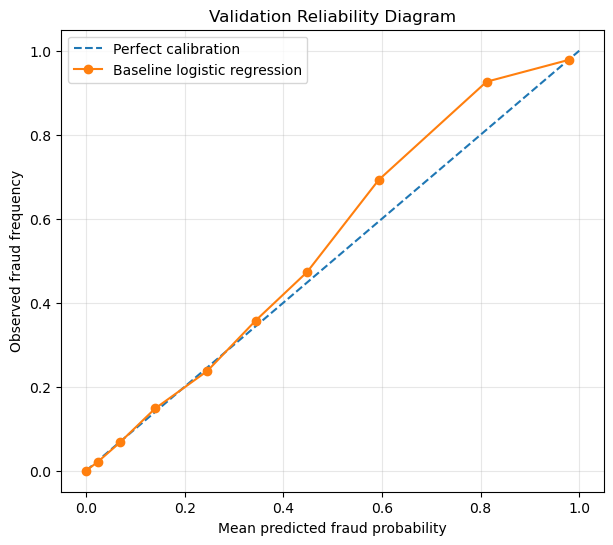

In [24]:
# ============================================================
# 4.3.5 — Probability Calibration Assessment
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import brier_score_loss, log_loss

# Prepare validation probabilities and observed outcomes
y_valid_array = np.asarray(y_valid)
p_valid = np.asarray(valid_probabilities)

# Evaluate probability prediction quality
model_brier = brier_score_loss(y_valid_array, p_valid)
model_log_loss = log_loss(
    y_valid_array, p_valid, labels=[0, 1]
)

# Construct a constant-probability reference from training data
training_prevalence = y_train.mean()

reference_probabilities = np.full(
    len(y_valid_array),
    training_prevalence
)

reference_brier = brier_score_loss(
    y_valid_array, reference_probabilities
)

reference_log_loss = log_loss(
    y_valid_array, reference_probabilities, labels=[0, 1]
)

# Display probability prediction metrics
print(f"Training fraud prevalence: {training_prevalence:.6f}")
print(f"Validation fraud prevalence: {y_valid_array.mean():.6f}")

print("\nProbability prediction metrics:")
print(f"Model Brier score:     {model_brier:.6f}")
print(f"Reference Brier score: {reference_brier:.6f}")
print(f"Model log loss:        {model_log_loss:.6f}")
print(f"Reference log loss:    {reference_log_loss:.6f}")

# Calculate calibration statistics in predefined score bands
calibration_data = pd.DataFrame({
    "predicted_probability": p_valid,
    "fraud": y_valid_array
})

calibration_edges = [
    0.0, 0.01, 0.05, 0.10, 0.20,
    0.30, 0.40, 0.50, 0.70, 0.90, 1.0
]

calibration_data["bin"] = pd.cut(
    calibration_data["predicted_probability"],
    bins=calibration_edges,
    include_lowest=True,
    right=False
)

# Ensure exact probability 1.0 is included in the last bin
calibration_data.loc[
    calibration_data["predicted_probability"] == 1.0,
    "bin"
] = calibration_data["bin"].cat.categories[-1]

calibration_summary = (
    calibration_data
    .groupby("bin", observed=True)
    .agg(
        Count=("fraud", "size"),
        Mean_predicted=("predicted_probability", "mean"),
        Observed_fraud_rate=("fraud", "mean")
    )
    .reset_index()
)

print("\nCalibration summary:")
display(calibration_summary.round(6))

# Plot the reliability diagram
plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    calibration_summary["Mean_predicted"],
    calibration_summary["Observed_fraud_rate"],
    marker="o",
    label="Baseline logistic regression"
)

plt.xlabel("Mean predicted fraud probability")
plt.ylabel("Observed fraud frequency")
plt.title("Validation Reliability Diagram")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Findings and Interpretation

Probability calibration was evaluated on the chronological validation partition using the Brier score, log loss, and a reliability diagram based on predefined risk-score intervals.

The baseline logistic regression model achieved a Brier score of 0.004312 and log loss of 0.016985. The constant-probability reference predictor, based on the training fraud prevalence of 0.012717, achieved a Brier score of 0.010881 and log loss of 0.060665.

Relative to the reference predictor, the fitted model reduced the Brier score by approximately 60.37% and log loss by approximately 72.00%. These results demonstrate substantially better probabilistic prediction performance, although neither metric measures calibration independently of discrimination.

The reliability diagram showed relatively close agreement between mean predicted probabilities and observed fraud frequencies across several low- and intermediate-risk intervals.

However, noticeable underprediction was observed in the [0.50, 0.70) and [0.70, 0.90) intervals. Their mean predicted probabilities were approximately 0.5933 and 0.8120, respectively, compared with observed fraud frequencies of approximately 0.6923 and 0.9262.

In contrast, the highest-risk interval [0.90, 1.00] showed close agreement between mean predicted probability (0.9798) and observed fraud frequency (0.9785).

The majority of validation transactions were concentrated in the lowest-risk interval, while several intermediate- and high-risk intervals contained comparatively few observations. Consequently, calibration estimates for individual intervals should be interpreted cautiously.

**Modeling decision:** Retain the uncalibrated logistic regression model as the baseline. The observed discrepancies justify considering probability recalibration in a subsequent modeling experiment, using a procedure that preserves chronological separation between calibration fitting and evaluation.

No calibration transformation or final operational threshold is selected in this subsection. The test partition remains untouched.

### 4.4 Three-Action Decision Policy

#### 4.4.1 Mathematical Formulation and Decision Assumptions

**Objective:** Formulate a three-action operational decision policy that maps the estimated fraud probabilities produced by the baseline logistic regression model into Approve, Review/Verify, and Escalate actions.

The baseline model estimates a binary fraud probability \(\hat p(X)\), while the operational system must choose among three actions. These are distinct problems: the dataset contains binary fraud labels, not three action labels.

We define a two-threshold decision rule:

\[
\delta(X)=
\begin{cases}
\text{Approve}, & \hat p(X)<\tau_L,\\
\text{Review}, & \tau_L\leq\hat p(X)<\tau_H,\\
\text{Escalate}, & \hat p(X)\geq\tau_H,
\end{cases}
\]

where \(0\leq\tau_L<\tau_H\leq1\).

The three decision regions are mutually exclusive and cover the full probability range.

**Decision-theoretic interpretation**

Let \(L(a,y)\) represent the operational loss of choosing action \(a\) when the true fraud state is \(y\). For a transaction with conditional fraud probability \(p\), the expected loss is

\[
R(a\mid p)=(1-p)L(a,0)+pL(a,1).
\]

If action costs and true conditional probabilities were known, a minimum-expected-loss decision would select

\[
\delta^*(p)=\arg\min_a R(a\mid p).
\]

In a simplified illustrative model with fraud-approval loss \(C_F\), fixed review cost \(C_R\), and unnecessary-escalation cost \(C_E\), the expected losses are \(pC_F\), \(C_R\), and \((1-p)C_E\), respectively.

Provided the assumed cost structure makes Review optimal over a nonempty interval, the resulting decision boundaries are

\[
\tau_L=C_R/C_F,\qquad
\tau_H=1-C_R/C_E.
\]

These expressions depend on strong assumptions about the effectiveness and costs of Review and Escalate. They are mathematical illustrations, not empirically established banking costs.

**Operational feasibility**

Review and escalation workloads must also satisfy available operational capacity. We will assess these workloads using validation transaction counts and percentages.

Because BankSim contains simulation steps rather than verified timestamps, we will not interpret transaction counts as actual hourly or daily workloads.

**Modeling decision**

No numerical thresholds or operational cost parameters are selected in this subsection. We will first evaluate candidate decision regions using validation probabilities and observed outcomes, then examine the implications of explicit cost and capacity assumptions.

The fitted baseline model remains unchanged, and the test partition remains reserved for final evaluation.

#### 4.4.2 Empirical Analysis of Candidate Decision Regions

**Objective:** Evaluate how selected pairs of lower and upper decision thresholds distribute validation transactions and actual fraud cases across Approve, Review/Verify, and Escalate.

For each threshold pair \((\tau_L,\tau_H)\), the decision regions are:

\[
\begin{aligned}
\mathcal A &= \{i:\hat p_i<\tau_L\},\\
\mathcal R &= \{i:\tau_L\leq\hat p_i<\tau_H\},\\
\mathcal E &= \{i:\hat p_i\geq\tau_H\}.
\end{aligned}
\]

For each action region, we calculate the total number of transactions, actual fraud cases, and legitimate transactions.

We also calculate the review and escalation workload percentages, the number of fraudulent transactions assigned directly to Approve, and the proportion of all fraud cases routed to Review or Escalate.

The candidate threshold pairs are illustrative operating configurations, chosen to compare narrower and broader review regions and different escalation boundaries. They are not derived from measured business costs or established investigation capacity.

A fraudulent transaction assigned to Review or Escalate is not automatically counted as prevented fraud. Similarly, a legitimate transaction assigned to Escalate is not necessarily rejected.

The analysis uses the previously computed validation probabilities and observed fraud labels. The baseline classifier is unchanged, and the chronological test partition remains untouched.

In [30]:
# ============================================================
# 4.4.2 — Empirical Analysis of Candidate Decision Regions
# ============================================================

import numpy as np
import pandas as pd

# Define illustrative lower and upper threshold pairs
candidate_policies = [
    (0.30, 0.50),
    (0.20, 0.50),
    (0.10, 0.50),
    (0.10, 0.70),
    (0.20, 0.70),
    (0.30, 0.70)
]

# Use the existing validation labels and model probabilities
actual_fraud = np.asarray(y_valid)
risk_scores = np.asarray(valid_probabilities)

total_transactions = len(actual_fraud)
total_fraud = int(actual_fraud.sum())

# Evaluate transaction and fraud distributions for each policy
policy_results = []

for lower_threshold, upper_threshold in candidate_policies:

    approve = risk_scores < lower_threshold

    review = (
        (risk_scores >= lower_threshold)
        & (risk_scores < upper_threshold)
    )

    escalate = risk_scores >= upper_threshold

    approve_count = int(approve.sum())
    review_count = int(review.sum())
    escalate_count = int(escalate.sum())

    approve_fraud = int(actual_fraud[approve].sum())
    review_fraud = int(actual_fraud[review].sum())
    escalate_fraud = int(actual_fraud[escalate].sum())

    policy_results.append({
        "Lower": lower_threshold,
        "Upper": upper_threshold,
        "Approve": approve_count,
        "Review": review_count,
        "Escalate": escalate_count,
        "Fraud approved": approve_fraud,
        "Fraud reviewed": review_fraud,
        "Fraud escalated": escalate_fraud,
        "Review (%)": 100 * review_count / total_transactions,
        "Escalate (%)": 100 * escalate_count / total_transactions,
        "Fraud routed (%)": (
            100 * (review_fraud + escalate_fraud) / total_fraud
        )
    })

# Assemble the policy comparison table
policy_df = pd.DataFrame(policy_results)

# Verify complete transaction and fraud accounting
assert (
    policy_df["Approve"]
    + policy_df["Review"]
    + policy_df["Escalate"]
    == total_transactions
).all()

assert (
    policy_df["Fraud approved"]
    + policy_df["Fraud reviewed"]
    + policy_df["Fraud escalated"]
    == total_fraud
).all()

# Display the results
display(
    policy_df.round({
        "Review (%)": 3,
        "Escalate (%)": 3,
        "Fraud routed (%)": 3
    })
)

,Lower,Upper,Approve,Review,Escalate,Fraud approved,Fraud reviewed,Fraud escalated,Review (%),Escalate (%),Fraud routed (%)
0,0.3,0.5,97279,230,685,358,93,629,0.234,0.698,66.852
1,0.2,0.5,97039,470,685,301,150,629,0.479,0.698,72.130
2,0.1,0.5,96398,1111,685,206,245,629,1.131,0.698,80.926
3,0.1,0.7,96398,1228,568,206,326,548,1.251,0.578,80.926
4,0.2,0.7,97039,587,568,301,231,548,0.598,0.578,72.130
5,0.3,0.7,97279,347,568,358,174,548,0.353,0.578,66.852


#### Findings and Interpretation

Six illustrative two-threshold decision policies were evaluated using the 98,194 transactions and 1,080 observed fraud cases in the chronological validation partition.

All candidate policies satisfied the transaction-accounting and fraud-accounting identities, confirming that the Approve, Review, and Escalate regions were mutually exclusive and collectively exhaustive.

**Effect of the lower threshold**

For a fixed upper threshold of 0.50, decreasing the lower threshold from 0.30 to 0.10 increased the review workload from 230 to 1,111 transactions, while reducing the number of fraudulent transactions assigned directly to Approve from 358 to 206.

Over the same comparison, combined fraud-routing coverage increased from 66.852% to 80.926%.

The 881 additional review assignments included 152 fraudulent and 729 legitimate transactions, demonstrating the trade-off between broader fraud coverage and increased investigation workload.

**Effect of the upper threshold**

For a fixed lower threshold of 0.10, increasing the upper threshold from 0.50 to 0.70 transferred 117 transactions from Escalate to Review, including 81 fraudulent and 36 legitimate transactions.

The number of approved transactions and approved fraud cases remained unchanged. Combined fraud-routing coverage therefore remained 80.926%.

This confirms that the lower threshold determines which transactions are approved, while the upper threshold determines how the remaining transactions are distributed between Review and Escalate.

**Operational interpretation**

The candidate policies exhibit different balances between fraud-routing coverage, review workload, and escalation workload.

For example, policy (0.10, 0.70) assigned 1,228 transactions to Review and 568 to Escalate, with 206 fraudulent transactions remaining in the Approve region. Its review and escalation workloads represented 1.251% and 0.578% of validation transactions, respectively.

The observed fraud counts in Review and Escalate represent routing outcomes, not confirmed fraud prevention. The BankSim dataset does not contain verification outcomes, intervention effectiveness, or measured operational action costs.

**Modeling decision**

No candidate policy is selected as optimal at this stage. The empirical results will support subsequent cost-sensitive and capacity-constrained analysis.

The baseline classifier remains unchanged, and the chronological test partition remains reserved for final evaluation.

#### 4.4.3 Operational Costs, Capacity Constraints, and Threshold Selection

**Objective:** Investigate how hypothetical operational costs, intervention effectiveness, and capacity constraints influence the preferred three-action decision policy.

The BankSim dataset provides binary fraud outcomes but does not provide measured investigation costs, intervention outcomes, or operational capacity. Consequently, we use explicitly hypothetical, normalized cost scenarios.

For each candidate policy, we calculate the empirical total loss:

\[
\widehat C
=
C_FF_A+C_RN_R+rC_FF_R
+C_E(N_E-F_E)+eC_FF_E.
\]

Here, \(F_A,F_R,F_E\) are the observed fraud counts in Approve, Review, and Escalate; \(N_R,N_E\) are the corresponding total workloads; \(C_F\) is the cost of approved fraud; \(C_R\) is the review cost; \(C_E\) is the cost of escalating a legitimate transaction; and \(r,e\) represent hypothetical residual fraud-loss fractions after Review and Escalate.

The review and escalation workload constraints are

\[
N_R/n\leq q_R,\qquad N_E/n\leq q_E.
\]

We will compare three illustrative cost scenarios, using a fixed set of candidate policies and explicit capacity assumptions.

**Interpretation boundaries**

- The costs are normalized illustrative units, not observed Canadian-dollar losses.
- Residual fraud-loss fractions are assumptions, not measured intervention effectiveness.
- Capacity percentages refer to the validation sample, not real hourly or daily staffing limits.
- A minimum-loss candidate is optimal only within the evaluated candidate set and specified assumptions.
- No production thresholds will be finalized from these experiments.

The baseline classifier remains unchanged, and the chronological test partition remains untouched.

In [34]:
# ============================================================
# 4.4.3 — Operational Cost and Capacity Sensitivity
# ============================================================

import pandas as pd
import numpy as np

# Define hypothetical normalized cost scenarios
cost_scenarios = {
    "A: Review effective": {
        "C_F": 100.0,
        "C_R": 1.0,
        "C_E": 5.0,
        "r": 0.10,
        "e": 0.05
    },
    "B: Review less effective": {
        "C_F": 100.0,
        "C_R": 2.0,
        "C_E": 5.0,
        "r": 0.50,
        "e": 0.05
    },
    "C: Escalation costly": {
        "C_F": 100.0,
        "C_R": 2.0,
        "C_E": 30.0,
        "r": 0.20,
        "e": 0.05
    }
}

# Define illustrative capacity limits
MAX_REVIEW_RATE = 0.015
MAX_ESCALATE_RATE = 0.007

# Evaluate empirical costs using Section 4.4.2 results
cost_results = []

for scenario_name, costs in cost_scenarios.items():

    for _, policy in policy_df.iterrows():

        lower = policy["Lower"]
        upper = policy["Upper"]

        n_review = policy["Review"]
        n_escalate = policy["Escalate"]

        fraud_approve = policy["Fraud approved"]
        fraud_review = policy["Fraud reviewed"]
        fraud_escalate = policy["Fraud escalated"]

        legitimate_escalate = n_escalate - fraud_escalate

        total_cost = (
            costs["C_F"] * fraud_approve
            + costs["C_R"] * n_review
            + costs["r"] * costs["C_F"] * fraud_review
            + costs["C_E"] * legitimate_escalate
            + costs["e"] * costs["C_F"] * fraud_escalate
        )

        review_rate = n_review / total_transactions
        escalate_rate = n_escalate / total_transactions

        feasible = (
            review_rate <= MAX_REVIEW_RATE
            and escalate_rate <= MAX_ESCALATE_RATE
        )

        cost_results.append({
            "Scenario": scenario_name,
            "Lower": lower,
            "Upper": upper,
            "Total cost": total_cost,
            "Cost per transaction": total_cost / total_transactions,
            "Review (%)": 100 * review_rate,
            "Escalate (%)": 100 * escalate_rate,
            "Feasible": feasible
        })

cost_df = pd.DataFrame(cost_results)

# Display all evaluated scenario-policy combinations
display(
    cost_df.round({
        "Total cost": 2,
        "Cost per transaction": 4,
        "Review (%)": 3,
        "Escalate (%)": 3
    })
)

# Identify the lowest-cost feasible candidate in each scenario
feasible_policies = cost_df.loc[cost_df["Feasible"]].copy()

if feasible_policies.empty:
    print("No candidate policy satisfies the capacity limits.")
else:
    best_indices = (
        feasible_policies
        .groupby("Scenario")["Total cost"]
        .idxmin()
    )

    best_candidates = (
        feasible_policies.loc[best_indices]
        .sort_values("Scenario")
        .reset_index(drop=True)
    )

    print("\nLowest-cost feasible candidate by scenario:")
    display(
        best_candidates.round({
            "Total cost": 2,
            "Cost per transaction": 4,
            "Review (%)": 3,
            "Escalate (%)": 3
        })
    )

,Scenario,Lower,Upper,Total cost,Cost per transaction,Review (%),Escalate (%),Feasible
0,A: Review effective,0.3,0.5,40385.0,0.4113,0.234,0.698,True
1,A: Review effective,0.2,0.5,35495.0,0.3615,0.479,0.698,True
2,A: Review effective,0.1,0.5,27586.0,0.2809,1.131,0.698,True
3,A: Review effective,0.1,0.7,27928.0,0.2844,1.251,0.578,True
4,A: Review effective,0.2,0.7,35837.0,0.3650,0.598,0.578,True
5,A: Review effective,0.3,0.7,40727.0,0.4148,0.353,0.578,True
6,B: Review less effective,0.3,0.5,44335.0,0.4515,0.234,0.698,True
7,B: Review less effective,0.2,0.5,41965.0,0.4274,0.479,0.698,True
8,B: Review less effective,0.1,0.5,38497.0,0.3921,1.131,0.698,True
9,B: Review less effective,0.1,0.7,42196.0,0.4297,1.251,0.578,True



Lowest-cost feasible candidate by scenario:


,Scenario,Lower,Upper,Total cost,Cost per transaction,Review (%),Escalate (%),Feasible
0,A: Review effective,0.1,0.5,27586.0,0.2809,1.131,0.698,True
1,B: Review less effective,0.1,0.5,38497.0,0.3921,1.131,0.698,True
2,C: Escalation costly,0.1,0.5,32547.0,0.3315,1.131,0.698,True


#### Findings and Interpretation

Three hypothetical operational cost scenarios were evaluated for the six candidate three-action policies previously examined in Section 4.4.2.

The scenarios differed in assumed review costs, residual fraud losses following Review, and costs of escalating legitimate transactions. All costs were expressed in normalized hypothetical units rather than observed financial losses.

**Cost-sensitive policy comparison**

Under all three scenarios, the lowest-cost feasible candidate among the evaluated threshold pairs was \((\tau_L,\tau_H)=(0.10,0.50)\).

The corresponding total empirical costs were 27,586 units in Scenario A, 38,497 units in Scenario B, and 32,547 units in Scenario C.

This candidate assigned 96,398 validation transactions to Approve, 1,111 to Review, and 685 to Escalate. It routed 874 of the 1,080 observed fraudulent transactions to Review or Escalate, corresponding to fraud-routing coverage of 80.926%, while 206 fraudulent transactions remained in the Approve region.

The consistent selection across the three scenarios indicates limited robustness within the evaluated assumptions and candidate set. It does not establish globally optimal thresholds or justify deployment.

**Effect of changing the escalation threshold**

For Scenario C, increasing the upper threshold from 0.50 to 0.70 while retaining the lower threshold of 0.10 increased total empirical cost from 32,547 to 32,916 units.

The 369-unit increase was explained by transferring 117 transactions from Escalate to Review, including 81 fraudulent and 36 legitimate transactions. The additional assumed residual fraud loss and review costs exceeded the savings associated with fewer unnecessary escalations.

**Capacity feasibility**

All evaluated candidate policies satisfied the illustrative review-capacity limit of 1.5% and escalation-capacity limit of 0.7% of validation transactions.

Consequently, the capacity constraints were nonbinding for the evaluated candidates. The results demonstrate cost sensitivity under feasible workloads, but do not yet show how restrictive operational capacity changes policy selection.

**Limitations and modeling decision**

The loss parameters and intervention-effectiveness assumptions were hypothetical. The dataset does not contain measured review costs, escalation outcomes, fraud-prevention effectiveness, or verified operational staffing capacity.

The candidate search space was limited to six predefined threshold pairs, and the sensitivity analysis did not establish optimality outside those candidates or assumptions.

The threshold pair (0.10, 0.50) is therefore retained only as the lowest-cost candidate in the current illustrative experiments, not as a finalized operational policy.

A subsequent capacity-sensitivity analysis is warranted before completing policy validation. The chronological test partition remains untouched.

#### 4.4.4 Validation and Interpretation of the Three-Action Decision Policy

**Objective:** Consolidate the empirical characteristics of the provisional three-action policy selected from the illustrative cost scenarios, including action-specific fraud concentrations, fraud-routing coverage, and intervention workload.

The provisional threshold pair is \((\tau_L,\tau_H)=(0.10,0.50)\). It was the lowest-cost feasible candidate among six evaluated policies under all three hypothetical cost scenarios.

We will construct an action-by-outcome matrix with three action rows (Approve, Review, Escalate) and two observed outcome columns (non-fraud, fraud).

For each action, we calculate the total number of transactions, actual fraud count, observed fraud concentration, percentage of all validation transactions, and percentage of all validation fraud cases.

We also calculate the combined intervention workload and fraud-routing coverage.

**Interpretation limitations**

The policy was selected using the same validation data on which its characteristics are being summarized. Consequently, the reported figures are descriptive development-set results, not independent estimates of future operational performance.

The BankSim dataset does not contain intervention outcomes, review effectiveness, actual fraud-prevention results, or measured operational costs.

The provisional policy remains subject to further modeling decisions and independent test-set evaluation. No deployment-ready thresholds are claimed.

In [39]:
# ============================================================
# 4.4.4 — Validation of the Provisional Three-Action Policy
# ============================================================

import numpy as np
import pandas as pd

# Define the provisional policy thresholds
LOWER_THRESHOLD = 0.10
UPPER_THRESHOLD = 0.50

# Apply the policy to existing validation risk scores
risk_scores = np.asarray(valid_probabilities)
actual_fraud = np.asarray(y_valid)

actions = np.select(
    [
        risk_scores < LOWER_THRESHOLD,
        risk_scores < UPPER_THRESHOLD
    ],
    [
        "Approve",
        "Review"
    ],
    default="Escalate"
)

# Construct the action-by-outcome matrix
action_matrix = pd.crosstab(
    pd.Categorical(
        actions,
        categories=["Approve", "Review", "Escalate"],
        ordered=True
    ),
    actual_fraud
)

action_matrix = action_matrix.reindex(
    columns=[0, 1],
    fill_value=0
)

action_matrix.index.name = "Action"
action_matrix.columns = ["Non-fraud", "Fraud"]

action_matrix["Total"] = action_matrix.sum(axis=1)

# Calculate action-specific operational statistics
action_summary = action_matrix.copy()

action_summary["Fraud concentration (%)"] = (
    100 * action_summary["Fraud"] / action_summary["Total"]
)

action_summary["Transactions (%)"] = (
    100 * action_summary["Total"] / len(actual_fraud)
)

action_summary["Share of all fraud (%)"] = (
    100 * action_summary["Fraud"] / actual_fraud.sum()
)

# Calculate combined intervention measures
intervention_count = int(
    action_matrix.loc[["Review", "Escalate"], "Total"].sum()
)

intervention_fraud = int(
    action_matrix.loc[["Review", "Escalate"], "Fraud"].sum()
)

intervention_workload = (
    100 * intervention_count / len(actual_fraud)
)

fraud_routing_coverage = (
    100 * intervention_fraud / actual_fraud.sum()
)

# Verify agreement with previous policy analysis
assert action_matrix["Total"].sum() == 98194
assert action_matrix["Fraud"].sum() == 1080

assert action_matrix.loc["Approve", "Total"] == 96398
assert action_matrix.loc["Approve", "Fraud"] == 206

assert action_matrix.loc["Review", "Total"] == 1111
assert action_matrix.loc["Review", "Fraud"] == 245

assert action_matrix.loc["Escalate", "Total"] == 685
assert action_matrix.loc["Escalate", "Fraud"] == 629

# Display results
print("Action-by-outcome matrix:")
display(action_matrix)

print("\nAction-specific operational summary:")
display(
    action_summary.round({
        "Fraud concentration (%)": 3,
        "Transactions (%)": 3,
        "Share of all fraud (%)": 3
    })
)

print("\nCombined intervention statistics:")
print(f"Transactions routed to intervention: {intervention_count:,}")
print(f"Intervention workload: {intervention_workload:.3f}%")
print(f"Fraud cases routed to intervention: {intervention_fraud:,}")
print(f"Fraud-routing coverage: {fraud_routing_coverage:.3f}%")

Action-by-outcome matrix:


,Non-fraud,Fraud,Total
Action,,,
Approve,96192,206,96398
Review,866,245,1111
Escalate,56,629,685



Action-specific operational summary:


,Non-fraud,Fraud,Total,Fraud concentration (%),Transactions (%),Share of all fraud (%)
Action,,,,,,
Approve,96192,206,96398,0.214,98.171,19.074
Review,866,245,1111,22.052,1.131,22.685
Escalate,56,629,685,91.825,0.698,58.241



Combined intervention statistics:
Transactions routed to intervention: 1,796
Intervention workload: 1.829%
Fraud cases routed to intervention: 874
Fraud-routing coverage: 80.926%


#### Findings and Interpretation

The provisional three-action decision policy, using lower and upper thresholds of 0.10 and 0.50, was evaluated descriptively on the chronological validation partition containing 98,194 transactions and 1,080 observed fraud cases.

The action-by-outcome matrix confirmed that all transactions were assigned to exactly one of the three decision regions and that the resulting transaction and fraud counts agreed with the preceding policy analysis.

**Action-specific fraud concentration**

The Approve region contained 96,398 transactions (98.171% of validation observations), including 206 fraudulent transactions. Its observed fraud concentration was 0.214%.

The Review region contained 1,111 transactions (1.131%), including 245 fraudulent transactions, corresponding to an observed fraud concentration of 22.052%.

The Escalate region contained 685 transactions (0.698%), including 629 fraudulent transactions, corresponding to an observed fraud concentration of 91.825%.

These results demonstrate substantial separation in observed fraud frequencies between the three risk-score regions.

**Combined intervention outcomes**

The Review and Escalate regions together contained 1,796 transactions, representing 1.829% of the validation partition.

Of these intervention assignments, 874 concerned actual fraudulent transactions and 922 concerned legitimate transactions.

Consequently, 80.926% of all observed fraud cases were routed to Review or Escalate, while 19.074% remained in the Approve region.

The combined intervention region is equivalent to classifying transactions as positive at threshold 0.10, which provides an additional consistency check against the threshold sensitivity analysis.

**Interpretation and limitations**

The three-action policy provides a descriptive separation of transactions into regions with different observed fraud concentrations and workloads.

However, fraud-routing coverage is not equivalent to realized fraud prevention. The dataset does not provide review outcomes, escalation effectiveness, intervention costs, or operational capacity measurements.

Furthermore, the provisional thresholds were compared and selected using the same validation partition. Therefore, these results represent development-set performance rather than an independent estimate of future policy effectiveness.

**Modeling decision**

Retain the threshold pair (0.10, 0.50) as a provisional, scenario-dependent policy configuration for subsequent comparison and testing.

Do not interpret the thresholds as globally optimal, economically validated, or deployment-ready.

The baseline logistic regression model remains unchanged, and the chronological test partition remains reserved for final evaluation.

### 4.5 Comparative Modeling: Logistic Regression versus Random Forest

#### 4.5.1 Mathematical Motivation and Experimental Design

**Objective:** Determine whether a nonlinear tree-based ensemble provides meaningful improvements over the baseline logistic regression model for fraud-risk prediction.

Logistic regression models the log-odds of fraud as a linear function of the transformed predictors. With transaction amount and category as baseline features, the current specification does not explicitly include nonlinear amount effects or amount-by-category interactions.

Random Forest constructs an ensemble of decision trees fitted using bootstrap sampling and randomized feature selection. Its predicted fraud probability is obtained by averaging the fraud-class probabilities produced by the individual trees.

Unlike logistic regression, Random Forest can represent nonlinear decision boundaries and interactions without requiring their explicit specification.

However, greater model flexibility may increase variance, computational cost, and sensitivity to training-data characteristics. It does not guarantee better predictive performance or probability calibration.

**Experimental design**

Both models will use the same chronological training and validation partitions and the same baseline features (`amount`, `category`).

Random Forest will be trained without class weighting or hyperparameter optimization in the initial comparison. A fixed random seed will support reproducibility.

The primary comparison metric will be validation Average Precision, supported by ROC-AUC, Brier score, and log loss.

Threshold-dependent operational comparisons will be considered separately because ranking quality, probability calibration, and operational decision performance are distinct properties.

**Modeling decision**

The Random Forest experiment will establish a second baseline before considering further model refinement. The chronological test partition remains untouched.

#### 4.5.2 Random Forest Training and Implementation

**Objective:** Construct and fit a Random Forest classifier using the same chronological training partition and baseline predictors employed for logistic regression.

Random Forest is an ensemble learning method that combines multiple decision trees. Each tree is trained on a bootstrap sample of the training observations, while randomized feature selection introduces additional diversity among trees.

For binary fraud classification, the forest's predicted probability is the average of the individual trees' predicted fraud-class probabilities.

The model uses the Gini impurity criterion for recursive tree splitting. This criterion measures class heterogeneity and is distinct from the operational loss function introduced in Section 4.4.

**Preprocessing**

The numerical predictor `amount` is passed through without scaling because tree-based splitting does not require feature standardization.

The categorical predictor `category` is one-hot encoded, with previously unseen categories handled using `handle_unknown="ignore"`.

Preprocessing and classification are combined in a scikit-learn Pipeline to prevent information leakage.

**Initial model configuration**

- Number of trees: 200.
- Splitting criterion: Gini impurity.
- Maximum tree depth: unrestricted.
- Minimum samples per leaf: 1.
- Bootstrap sampling: enabled.
- Class weighting: none.
- Random seed: 42.
- Parallel processing: enabled.

These settings define an initial comparison model, not an optimized Random Forest configuration. In particular, unrestricted tree depth and a minimum leaf size of one may produce highly specific terminal leaves, potentially affecting generalization and probability calibration.

The model is fitted using only the chronological training partition. Validation and test observations are excluded from fitting.

In [44]:
# ============================================================
# 4.5.2 — Random Forest Training and Implementation
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

import numpy as np
import pandas as pd
import time

# ------------------------------------------------------------
# 1. Define baseline predictors
# ------------------------------------------------------------

numeric_features = ["amount"]
categorical_features = ["category"]

# ------------------------------------------------------------
# 2. Define Random Forest preprocessing
# ------------------------------------------------------------

rf_preprocessing = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

# ------------------------------------------------------------
# 3. Define Random Forest classifier
# ------------------------------------------------------------

rf_classifier = RandomForestClassifier(
    n_estimators=200,
    criterion="gini",
    max_depth=None,
    min_samples_leaf=1,
    max_features="sqrt",
    bootstrap=True,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# 4. Construct the modeling pipeline
# ------------------------------------------------------------

rf_model = Pipeline(
    steps=[
        ("preprocessing", rf_preprocessing),
        ("classifier", rf_classifier)
    ]
)

# ------------------------------------------------------------
# 5. Fit on the chronological training partition only
# ------------------------------------------------------------

start_time = time.perf_counter()

rf_model.fit(X_train, y_train)

training_time = time.perf_counter() - start_time

# ------------------------------------------------------------
# 6. Verify the fitted model
# ------------------------------------------------------------

fitted_rf = rf_model.named_steps["classifier"]
fitted_preprocessor = rf_model.named_steps["preprocessing"]

feature_names = fitted_preprocessor.get_feature_names_out()

tree_depths = np.array([
    tree.get_depth()
    for tree in fitted_rf.estimators_
])

leaf_counts = np.array([
    tree.get_n_leaves()
    for tree in fitted_rf.estimators_
])

print("Random Forest training completed.")
print(f"Training observations: {len(X_train):,}")
print(f"Training fraud cases: {int(np.sum(y_train)):,}")
print(f"Training time (seconds): {training_time:.2f}")

print("\nModel configuration:")
print(f"Number of trees: {fitted_rf.n_estimators}")
print(f"Criterion: {fitted_rf.criterion}")
print(f"Maximum depth parameter: {fitted_rf.max_depth}")
print(f"Minimum samples per leaf: {fitted_rf.min_samples_leaf}")
print(f"Class weighting: {fitted_rf.class_weight}")

print("\nFitted model structure:")
print(f"Transformed feature count: {len(feature_names)}")
print(f"Mean tree depth: {tree_depths.mean():.2f}")
print(f"Minimum tree depth: {tree_depths.min()}")
print(f"Maximum tree depth: {tree_depths.max()}")
print(f"Mean number of leaves: {leaf_counts.mean():.2f}")

print("\nTransformed features:")
for name in feature_names:
    print(name)

# ------------------------------------------------------------
# 7. Consistency checks
# ------------------------------------------------------------

assert len(X_train) == len(y_train)
assert len(X_train) == 396332
assert int(np.sum(y_train)) == 5040

assert fitted_rf.n_estimators == 200
assert len(fitted_rf.estimators_) == 200
assert len(feature_names) == 16

print("\nAll consistency checks passed.")

Random Forest training completed.
Training observations: 396,332
Training fraud cases: 5,040
Training time (seconds): 62.61

Model configuration:
Number of trees: 200
Criterion: gini
Maximum depth parameter: None
Minimum samples per leaf: 1
Class weighting: None

Fitted model structure:
Transformed feature count: 16
Mean tree depth: 48.84
Minimum tree depth: 35
Maximum tree depth: 71
Mean number of leaves: 2245.59

Transformed features:
numeric__amount
categorical__category_'es_barsandrestaurants'
categorical__category_'es_contents'
categorical__category_'es_fashion'
categorical__category_'es_food'
categorical__category_'es_health'
categorical__category_'es_home'
categorical__category_'es_hotelservices'
categorical__category_'es_hyper'
categorical__category_'es_leisure'
categorical__category_'es_otherservices'
categorical__category_'es_sportsandtoys'
categorical__category_'es_tech'
categorical__category_'es_transportation'
categorical__category_'es_travel'
categorical__category_'es_wel

#### Findings and Interpretation

The initial Random Forest classifier was successfully trained using the chronological training partition containing 396,332 transactions, including 5,040 observed fraud cases.

The model consisted of 200 decision trees using Gini impurity, bootstrap sampling, randomized feature selection, unrestricted maximum depth, and a minimum leaf size of one. No class weighting was applied.

**Preprocessing verification**

The fitted preprocessing pipeline produced 16 transformed features: one unscaled numerical feature (`amount`) and 15 one-hot-encoded category indicators.

This confirms that Random Forest used the same two underlying predictors as the logistic regression baseline, with preprocessing appropriate for tree-based learning.

**Training and structural complexity**

The measured training time was 62.61 seconds in the current execution environment.

The fitted trees had an average maximum depth of 48.84, with individual depths ranging from 35 to 71. The mean number of terminal leaves was 2,245.59 per tree.

These results indicate that the initial forest contains structurally complex decision trees and can represent detailed nonlinear partitions of the predictor space.

The unrestricted depth and minimum leaf size of one permit highly specific terminal regions. This flexibility may help capture relationships not represented by the baseline logistic regression model, but it may also increase sensitivity to training-specific patterns.

**Interpretation limitations**

Tree depth and leaf count describe structural complexity; they do not establish predictive superiority, overfitting, or probability calibration quality.

The observed training time is environment-dependent and is not yet a controlled computational comparison with logistic regression.

**Modeling decision**

Retain the fitted Random Forest as the initial nonlinear comparison model.

Proceed to validation-based evaluation using Average Precision, ROC-AUC, Brier score, and log loss, while preserving the chronological test partition for final evaluation.

All training-data and fitted-model consistency checks passed.

#### 4.5.3 Comparative Validation Performance

**Objective:** Compare the predictive discrimination and probabilistic accuracy of the fitted Logistic Regression and Random Forest classifiers using the same chronological validation partition.

Both models were trained using the same underlying predictors (`amount`, `category`) and the same chronological training observations. Their preprocessing pipelines differ appropriately according to the learning algorithm.

No model retraining, hyperparameter optimization, or test-set evaluation is performed in this subsection.

**Evaluation metrics**

1. **Average Precision (AP):** Primary metric for evaluating fraud-ranking performance under class imbalance. Higher values are better.
2. **ROC-AUC:** Secondary measure of discrimination between fraudulent and legitimate transactions. Higher values are better.
3. **Brier score:** Mean squared error of predicted fraud probabilities. Lower values are better.
4. **Log loss:** Mean negative logarithmic likelihood of observed outcomes. Lower values are better.

The validation fraud prevalence provides the reference level for interpreting Average Precision. Previously computed Logistic Regression results provide a consistency check.

Prediction time will also be recorded, but the measurements are environment-dependent and should not be interpreted as a controlled computational benchmark.

**Interpretation criteria**

Improved discrimination does not necessarily imply improved probability calibration. Likewise, better probability scores do not automatically imply a superior operational policy.

The comparison will establish whether Random Forest provides measurable advantages over Logistic Regression and whether further model refinement is justified.

The chronological test partition remains untouched.

In [48]:
# ============================================================
# 4.5.3 — Comparative Validation Performance
# ============================================================

import numpy as np
import pandas as pd
import time

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss
)

# ------------------------------------------------------------
# 1. Verify validation data
# ------------------------------------------------------------

y_valid_array = np.asarray(y_valid).ravel()

assert len(X_valid) == len(y_valid_array)
assert len(y_valid_array) == 98194
assert int(y_valid_array.sum()) == 1080
assert set(np.unique(y_valid_array)) == {0, 1}

validation_prevalence = y_valid_array.mean()

# ------------------------------------------------------------
# 2. Generate probabilities from fitted models
# ------------------------------------------------------------

start_time = time.perf_counter()

lr_valid_probabilities = (
    baseline_model.predict_proba(X_valid)[:, 1]
)

lr_prediction_time = time.perf_counter() - start_time

start_time = time.perf_counter()

rf_valid_probabilities = (
    rf_model.predict_proba(X_valid)[:, 1]
)

rf_prediction_time = time.perf_counter() - start_time

# ------------------------------------------------------------
# 3. Verify probability outputs
# ------------------------------------------------------------

for model_name, probabilities in [
    ("Logistic Regression", lr_valid_probabilities),
    ("Random Forest", rf_valid_probabilities)
]:
    assert probabilities.shape == (len(y_valid_array),)
    assert np.all(np.isfinite(probabilities))
    assert np.all((probabilities >= 0) & (probabilities <= 1))

# Verify Logistic Regression predictions agree with
# the probabilities already used in Sections 4.3–4.4.

assert np.allclose(
    lr_valid_probabilities,
    np.asarray(valid_probabilities)
)

# ------------------------------------------------------------
# 4. Define common evaluation function
# ------------------------------------------------------------

def evaluate_validation_model(
    y_true,
    probabilities,
    prediction_time
):
    return {
        "Average Precision": average_precision_score(
            y_true, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        ),
        "Brier score": brier_score_loss(
            y_true, probabilities
        ),
        "Log loss": log_loss(
            y_true, probabilities,
            labels=[0, 1]
        ),
        "Prediction time (s)": prediction_time
    }

# ------------------------------------------------------------
# 5. Evaluate both models
# ------------------------------------------------------------

comparison_results = {
    "Logistic Regression": evaluate_validation_model(
        y_valid_array,
        lr_valid_probabilities,
        lr_prediction_time
    ),
    "Random Forest": evaluate_validation_model(
        y_valid_array,
        rf_valid_probabilities,
        rf_prediction_time
    )
}

comparison_df = pd.DataFrame.from_dict(
    comparison_results,
    orient="index"
)

comparison_df.index.name = "Model"

# ------------------------------------------------------------
# 6. Display comparison
# ------------------------------------------------------------

print("Validation observations:", len(y_valid_array))
print("Validation fraud cases:", int(y_valid_array.sum()))
print(
    f"Validation fraud prevalence: "
    f"{validation_prevalence:.6f}"
)

print("\nComparative validation performance:")

display(
    comparison_df.round({
        "Average Precision": 6,
        "ROC-AUC": 6,
        "Brier score": 6,
        "Log loss": 6,
        "Prediction time (s)": 3
    })
)

# ------------------------------------------------------------
# 7. Calculate Random Forest minus Logistic Regression
# ------------------------------------------------------------

metric_columns = [
    "Average Precision",
    "ROC-AUC",
    "Brier score",
    "Log loss"
]

metric_differences = (
    comparison_df.loc["Random Forest", metric_columns]
    - comparison_df.loc["Logistic Regression", metric_columns]
)

difference_df = pd.DataFrame({
    "RF - LR": metric_differences,
    "Preferred direction": [
        "Positive",
        "Positive",
        "Negative",
        "Negative"
    ]
})

print("\nMetric differences:")
display(difference_df.round(6))

# ------------------------------------------------------------
# 8. Verify established Logistic Regression metrics
# ------------------------------------------------------------

assert np.isclose(
    comparison_df.loc[
        "Logistic Regression", "Average Precision"
    ],
    0.783930,
    atol=1e-6
)

assert np.isclose(
    comparison_df.loc[
        "Logistic Regression", "ROC-AUC"
    ],
    0.992308,
    atol=1e-6
)

print("\nAll consistency checks passed.")

Validation observations: 98194
Validation fraud cases: 1080
Validation fraud prevalence: 0.010999

Comparative validation performance:


,Average Precision,ROC-AUC,Brier score,Log loss,Prediction time (s)
Model,,,,,
Logistic Regression,0.783930,0.992308,0.004312,0.016985,0.199
Random Forest,0.708612,0.908137,0.005720,0.084423,0.268



Metric differences:


,RF - LR,Preferred direction
Average Precision,-0.075318,Positive
ROC-AUC,-0.084171,Positive
Brier score,0.001408,Negative
Log loss,0.067438,Negative



All consistency checks passed.


#### Findings and Interpretation

The fitted Logistic Regression and Random Forest classifiers were evaluated on the same chronological validation partition containing 98,194 transactions, including 1,080 observed fraud cases (fraud prevalence approximately 1.0999%).

Both classifiers used the same underlying predictors, transaction amount and category. No retraining or hyperparameter optimization was performed during this evaluation.

**Discrimination performance**

Logistic Regression achieved an Average Precision of 0.783930, compared with 0.708612 for Random Forest. The difference of −0.075318 indicates that the initial Random Forest provided weaker precision-recall performance.

ROC-AUC was also higher for Logistic Regression (0.992308) than for Random Forest (0.908137), with a difference of −0.084171.

Consequently, Logistic Regression outperformed the initial Random Forest on both discrimination metrics, including Average Precision, the primary metric selected for this project.

**Probability prediction quality**

Logistic Regression achieved a Brier score of 0.004312 and log loss of 0.016985.

The corresponding Random Forest values were 0.005720 and 0.084423.

Because lower values are preferable for both metrics, Logistic Regression also demonstrated better aggregate probability-prediction performance on the validation partition.

The substantially higher Random Forest log loss suggests that some probability estimates may be especially inaccurate or overconfident. However, this possibility requires further investigation; aggregate log loss alone does not identify the responsible observations or establish a specific cause.

**Computational observations**

Measured validation prediction times were 0.199 seconds for Logistic Regression and 0.268 seconds for Random Forest.

These timings describe the current execution environment and are not treated as a controlled computational benchmark.

**Interpretation of model complexity**

The Random Forest contained 200 trees with an average depth of 48.84 and approximately 2,245.59 leaves per tree.

Despite its greater representational flexibility, the initial Random Forest configuration did not improve validation discrimination or probability-prediction quality.

This finding is consistent with possible excessive model complexity, but overfitting cannot be established from the reported validation metrics and tree structures alone.

**Modeling decision**

Retain Logistic Regression as the current leading baseline because it outperformed the initial Random Forest across all four evaluation metrics.

Before excluding Random Forest from further consideration, investigate whether modest regularization of tree complexity improves its validation performance.

Any subsequent tuning must use the development data only. The chronological test partition remains untouched.

#### 4.5.4 Random Forest Complexity and Regularization Analysis

**Objective:** Investigate whether restricting individual tree complexity improves the validation performance of Random Forest.

The initial Random Forest configuration contained 200 trees with unrestricted maximum depth and a minimum leaf size of one. Its validation performance was inferior to Logistic Regression across Average Precision, ROC-AUC, Brier score, and log loss.

Two regularization parameters are examined:

- `max_depth`: the maximum permitted depth of each decision tree.
- `min_samples_leaf`: the minimum number of training samples required in each terminal leaf.

Five predefined regularized configurations will be evaluated alongside the original fitted Random Forest.

All configurations use the same chronological training and validation partitions, baseline predictors, preprocessing strategy, number of trees, splitting criterion, bootstrap setting, and random seed.

**Evaluation strategy**

Average Precision is the primary model-selection metric. ROC-AUC, Brier score, and log loss are secondary metrics.

The structural complexity of each fitted forest will also be summarized using mean tree depth and mean number of leaves.

The experiment is exploratory: selecting a configuration based on validation results introduces model-selection dependence. Performance reported on this validation partition is therefore not an independent estimate of the selected model's future performance.

No test-set observations are used.

**Interpretation**

Improvement after regularization would indicate that the modified configuration performs better on the validation partition. It would not, by itself, establish that the original model was overfitting.

The best regularized Random Forest will subsequently be compared with the unchanged Logistic Regression baseline.

In [52]:
# ============================================================
# 4.5.4 — Random Forest Regularization Analysis
# ============================================================

import numpy as np
import pandas as pd
import time

from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss
)

# ------------------------------------------------------------
# 1. Define a small, predefined configuration set
# ------------------------------------------------------------

rf_configurations = [
    {"name": "RF-1", "max_depth": 20, "min_samples_leaf": 5},
    {"name": "RF-2", "max_depth": 15, "min_samples_leaf": 10},
    {"name": "RF-3", "max_depth": 10, "min_samples_leaf": 20},
    {"name": "RF-4", "max_depth": 15, "min_samples_leaf": 50},
    {"name": "RF-5", "max_depth": 10, "min_samples_leaf": 100},
]

rf_models = {"RF-0": rf_model}
rf_probabilities = {"RF-0": rf_valid_probabilities}

# ------------------------------------------------------------
# 2. Record the original fitted Random Forest
# ------------------------------------------------------------

def summarize_forest(name, model, probabilities, fit_time=np.nan):

    forest = model.named_steps["classifier"]

    depths = np.array([
        tree.get_depth() for tree in forest.estimators_
    ])

    leaves = np.array([
        tree.get_n_leaves() for tree in forest.estimators_
    ])

    return {
        "Model": name,
        "Max depth": (
            "None" if forest.max_depth is None
            else str(forest.max_depth)
        ),
        "Min leaf": forest.min_samples_leaf,
        "Mean tree depth": depths.mean(),
        "Mean leaves": leaves.mean(),
        "Average Precision": average_precision_score(
            y_valid, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_valid, probabilities
        ),
        "Brier score": brier_score_loss(
            y_valid, probabilities
        ),
        "Log loss": log_loss(
            y_valid, probabilities,
            labels=[0, 1]
        ),
        "Fit time (s)": fit_time
    }


rf_regularization_results = [
    summarize_forest(
        "RF-0",
        rf_model,
        rf_valid_probabilities
    )
]

# ------------------------------------------------------------
# 3. Train and evaluate the regularized configurations
# ------------------------------------------------------------

for config in rf_configurations:

    name = config["name"]

    # Clone the original pipeline to preserve preprocessing
    # and all unchanged classifier settings.
    model = clone(rf_model)

    model.set_params(
        classifier__max_depth=config["max_depth"],
        classifier__min_samples_leaf=config["min_samples_leaf"]
    )

    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    fit_time = time.perf_counter() - start_time

    probabilities = model.predict_proba(X_valid)[:, 1]

    rf_models[name] = model
    rf_probabilities[name] = probabilities

    rf_regularization_results.append(
        summarize_forest(
            name,
            model,
            probabilities,
            fit_time
        )
    )

    print(f"{name} completed in {fit_time:.2f} seconds.")

# ------------------------------------------------------------
# 4. Construct the comparison table
# ------------------------------------------------------------

rf_regularization_df = pd.DataFrame(
    rf_regularization_results
).set_index("Model")

print("\nRandom Forest regularization results:")

display(
    rf_regularization_df.round({
        "Mean tree depth": 2,
        "Mean leaves": 2,
        "Average Precision": 6,
        "ROC-AUC": 6,
        "Brier score": 6,
        "Log loss": 6,
        "Fit time (s)": 2
    })
)

# ------------------------------------------------------------
# 5. Select the best RF by validation Average Precision
# ------------------------------------------------------------

best_rf_name = (
    rf_regularization_df["Average Precision"].idxmax()
)

best_rf_model = rf_models[best_rf_name]
best_rf_valid_probabilities = rf_probabilities[best_rf_name]

print("\nBest Random Forest by validation Average Precision:")
print(best_rf_name)

display(
    rf_regularization_df.loc[[best_rf_name]].round(6)
)

# ------------------------------------------------------------
# 6. Compare the selected RF with Logistic Regression
# ------------------------------------------------------------

lr_metrics = comparison_df.loc[
    "Logistic Regression",
    ["Average Precision", "ROC-AUC", "Brier score", "Log loss"]
]

best_rf_metrics = rf_regularization_df.loc[
    best_rf_name,
    ["Average Precision", "ROC-AUC", "Brier score", "Log loss"]
]

final_comparison_df = pd.DataFrame({
    "Logistic Regression": lr_metrics,
    "Best Random Forest": best_rf_metrics
})

final_comparison_df["RF - LR"] = (
    final_comparison_df["Best Random Forest"]
    - final_comparison_df["Logistic Regression"]
)

print("\nLogistic Regression versus selected Random Forest:")
display(final_comparison_df.round(6))

# ------------------------------------------------------------
# 7. Consistency checks
# ------------------------------------------------------------

assert len(rf_regularization_df) == 6
assert len(rf_models) == 6
assert len(rf_probabilities) == 6

assert np.isclose(
    rf_regularization_df.loc["RF-0", "Average Precision"],
    comparison_df.loc["Random Forest", "Average Precision"]
)

assert all(
    len(probabilities) == len(y_valid)
    for probabilities in rf_probabilities.values()
)

print("\nAll consistency checks passed.")

RF-1 completed in 34.29 seconds.
RF-2 completed in 23.82 seconds.
RF-3 completed in 16.31 seconds.
RF-4 completed in 22.54 seconds.
RF-5 completed in 16.57 seconds.

Random Forest regularization results:


,Max depth,Min leaf,Mean tree depth,Mean leaves,Average Precision,ROC-AUC,Brier score,Log loss,Fit time (s)
Model,,,,,,,,,
RF-0,None,1,48.84,2245.59,0.708612,0.908137,0.005720,0.084423,NaN
RF-1,20,5,20.00,780.52,0.792198,0.991686,0.004142,0.016680,34.29
RF-2,15,10,15.00,335.82,0.805055,0.992544,0.004003,0.015751,23.82
RF-3,10,20,10.00,106.60,0.807737,0.992853,0.004038,0.015968,16.31
RF-4,15,50,14.98,150.60,0.803650,0.992634,0.004108,0.016025,22.54
RF-5,10,100,10.00,52.32,0.797432,0.992811,0.004258,0.016543,16.57



Best Random Forest by validation Average Precision:
RF-3


,Max depth,Min leaf,Mean tree depth,Mean leaves,Average Precision,ROC-AUC,Brier score,Log loss,Fit time (s)
Model,,,,,,,,,
RF-3,10,20,10.0,106.605,0.807737,0.992853,0.004038,0.015968,16.309822



Logistic Regression versus selected Random Forest:


,Logistic Regression,Best Random Forest,RF - LR
Average Precision,0.783930,0.807737,0.023808
ROC-AUC,0.992308,0.992853,0.000545
Brier score,0.004312,0.004038,-0.000274
Log loss,0.016985,0.015968,-0.001017



All consistency checks passed.


#### Findings and Interpretation

Five predefined regularized Random Forest configurations were trained and evaluated alongside the original unrestricted Random Forest using the same chronological training and validation partitions.

The experiment investigated the effects of maximum tree depth and minimum samples per leaf on model complexity, discrimination, and probability-prediction quality.

**Effect of regularization**

The original Random Forest (RF-0) achieved validation Average Precision of 0.708612, ROC-AUC of 0.908137, Brier score of 0.005720, and log loss of 0.084423.

All five regularized configurations improved upon RF-0 across these four metrics.

The strongest configuration by the predefined primary metric, Average Precision, was RF-3, with `max_depth=10` and `min_samples_leaf=20`.

RF-3 achieved Average Precision of 0.807737, ROC-AUC of 0.992853, Brier score of 0.004038, and log loss of 0.015968.

Relative to RF-0, RF-3 improved Average Precision by 0.099125 and ROC-AUC by 0.084716, while reducing Brier score by 0.001682 and log loss by 0.068455.

**Structural complexity**

RF-0 had an average tree depth of 48.84 and approximately 2,245.59 terminal leaves per tree.

RF-3 reduced the average depth to 10.00 and the mean number of leaves to 106.60.

This substantial reduction in complexity was accompanied by improved validation performance, indicating that regularization was beneficial for the evaluated Random Forest configurations.

The experiment does not independently prove overfitting in RF-0, because training-versus-validation performance was not examined.

**Comparison with Logistic Regression**

The Logistic Regression baseline achieved Average Precision of 0.783930, ROC-AUC of 0.992308, Brier score of 0.004312, and log loss of 0.016985.

RF-3 outperformed Logistic Regression on all four validation metrics. The Average Precision advantage was approximately 0.023808, while the ROC-AUC advantage was comparatively small at 0.000545.

RF-2 achieved slightly lower Brier score (0.004003) and log loss (0.015751) than RF-3, demonstrating that the configuration with the best discrimination metric need not have the best probability-prediction quality.

**Modeling decision**

Retain RF-3 as the leading Random Forest configuration according to the predefined primary metric, Average Precision.

Retain RF-2 as a relevant alternative for probability-quality analysis and Logistic Regression as the established linear baseline.

The results support further investigation of probability calibration and three-action operational behavior before selecting a final model-policy combination.

Because model selection used the validation partition, the selected configuration's validation performance is not an independent estimate of future performance.

The chronological test partition remains untouched.

#### 4.5.5 Comparative Probability Calibration and Risk-Score Analysis

**Objective:** Compare the probability estimates produced by Logistic Regression and the two leading regularized Random Forest configurations, RF-2 and RF-3, using the chronological validation partition.

Although RF-3 achieved the highest validation Average Precision among the evaluated models, probability-ranking performance alone does not establish whether its numerical risk scores are sufficiently reliable for cost-sensitive operational decisions.

**Calibration diagnostics**

The analysis will use common, predefined probability intervals to compare:

- Mean predicted fraud probability.
- Observed fraud frequency.
- Number of transactions and observed fraud cases per interval.
- Difference between observed and predicted fraud frequency.
- Frequency of very low and very high predicted probabilities.

A reliability diagram will display observed fraud frequencies against mean predicted probabilities for each model. The diagonal represents ideal calibration.

Brier score and log loss will be retained as complementary aggregate probability-quality metrics.

**Interpretation limitations**

Calibration is assessed descriptively using the same validation partition previously used for Random Forest configuration selection. The resulting diagnostics are not an independent evaluation of the selected models.

The dataset does not establish that the predicted probabilities will remain calibrated under changes in transaction populations, fraud prevalence, or operational conditions.

No calibration transformation will be fitted in this subsection. Any subsequent calibration procedure must use appropriately separated development data to avoid information leakage and overly optimistic evaluation.

The chronological test partition remains untouched.


Calibration summary: Logistic Regression


,Bin,Transactions,Fraud,Mean_predicted,Observed_frequency,Calibration_gap
0,"[0.00, 0.01)",89828,13,0.000150,0.000145,-0.000006
1,"[0.01, 0.05)",5431,116,0.024061,0.021359,-0.002702
2,"[0.05, 0.10)",1139,77,0.068902,0.067603,-0.001299
3,"[0.10, 0.20)",641,95,0.140097,0.148206,0.008109
4,"[0.20, 0.30)",240,57,0.245881,0.237500,-0.008381
5,"[0.30, 0.40)",137,49,0.344014,0.357664,0.013651
6,"[0.40, 0.50)",93,44,0.448201,0.473118,0.024918
7,"[0.50, 0.70)",117,81,0.593260,0.692308,0.099048
8,"[0.70, 0.90)",149,138,0.812044,0.926174,0.114130
9,"[0.90, 1.00]",419,410,0.979840,0.978520,-0.001320



Calibration summary: RF-2


,Bin,Transactions,Fraud,Mean_predicted,Observed_frequency,Calibration_gap
10,"[0.00, 0.01)",90701,28,0.000199,0.000309,0.000110
11,"[0.01, 0.05)",4943,123,0.025864,0.024884,-0.000981
12,"[0.05, 0.10)",943,65,0.068309,0.068929,0.000620
13,"[0.10, 0.20)",420,55,0.144690,0.130952,-0.013737
14,"[0.20, 0.30)",258,69,0.244949,0.267442,0.022493
15,"[0.30, 0.40)",104,27,0.341122,0.259615,-0.081506
16,"[0.40, 0.50)",80,33,0.443969,0.412500,-0.031469
17,"[0.50, 0.70)",116,75,0.592028,0.646552,0.054524
18,"[0.70, 0.90)",117,100,0.825208,0.854701,0.029493
19,"[0.90, 1.00]",512,505,0.981949,0.986328,0.004379



Calibration summary: RF-3


,Bin,Transactions,Fraud,Mean_predicted,Observed_frequency,Calibration_gap
20,"[0.00, 0.01)",88500,0,0.000307,0.000000,-0.000307
21,"[0.01, 0.05)",7000,139,0.022455,0.019857,-0.002598
22,"[0.05, 0.10)",1097,68,0.064534,0.061987,-0.002547
23,"[0.10, 0.20)",451,76,0.144580,0.168514,0.023934
24,"[0.20, 0.30)",217,62,0.244258,0.285714,0.041457
25,"[0.30, 0.40)",137,34,0.339609,0.248175,-0.091433
26,"[0.40, 0.50)",55,25,0.460039,0.454545,-0.005494
27,"[0.50, 0.70)",133,96,0.589371,0.721805,0.132433
28,"[0.70, 0.90)",127,108,0.818839,0.850394,0.031554
29,"[0.90, 1.00]",477,472,0.962042,0.989518,0.027476


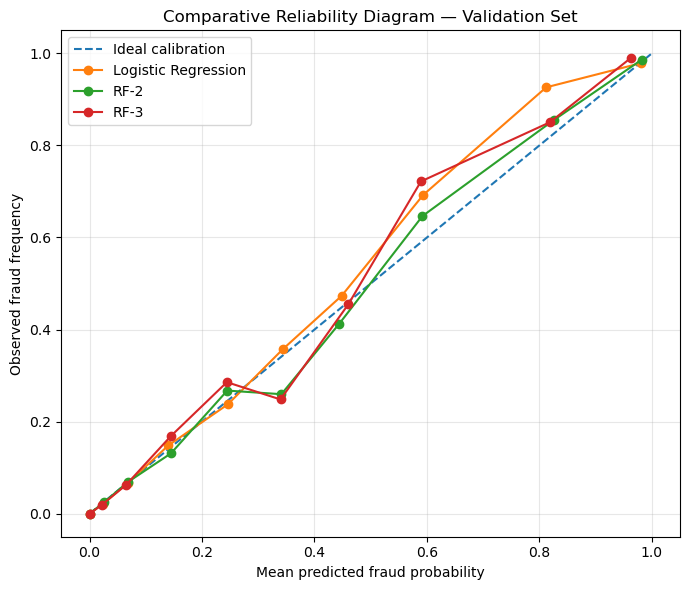


Probability distribution summary:


,Mean probability,Median probability,P >= 0.50 (%),P >= 0.90 (%),P <= 0.01 (%),Exact zero (%),Exact one (%),Brier score,Log loss
Model,,,,,,,,,
Logistic Regression,0.010808,0.000021,0.697599,0.426706,91.480131,0.0,0.026478,0.004312,0.016985
RF-2,0.010930,0.000005,0.758702,0.521417,92.369188,0.0,0.000000,0.004003,0.015751
RF-3,0.011064,0.000094,0.750555,0.485773,90.127706,0.0,0.000000,0.004038,0.015968



All consistency checks passed.


In [56]:
# ============================================================
# 4.5.5 — Comparative Probability Calibration
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import brier_score_loss, log_loss

# ------------------------------------------------------------
# 1. Collect existing validation predictions
# ------------------------------------------------------------

y_true = np.asarray(y_valid).ravel()

model_probabilities = {
    "Logistic Regression": np.asarray(lr_valid_probabilities),
    "RF-2": np.asarray(rf_probabilities["RF-2"]),
    "RF-3": np.asarray(rf_probabilities["RF-3"])
}

assert len(y_true) == 98194
assert int(y_true.sum()) == 1080

for name, probabilities in model_probabilities.items():
    assert len(probabilities) == len(y_true)
    assert np.all(np.isfinite(probabilities))
    assert np.all((probabilities >= 0) & (probabilities <= 1))

# ------------------------------------------------------------
# 2. Define common calibration intervals
# ------------------------------------------------------------

bin_edges = [
    0.00, 0.01, 0.05, 0.10, 0.20,
    0.30, 0.40, 0.50, 0.70, 0.90, 1.00
]

bin_labels = [
    "[0.00, 0.01)",
    "[0.01, 0.05)",
    "[0.05, 0.10)",
    "[0.10, 0.20)",
    "[0.20, 0.30)",
    "[0.30, 0.40)",
    "[0.40, 0.50)",
    "[0.50, 0.70)",
    "[0.70, 0.90)",
    "[0.90, 1.00]"
]

# ------------------------------------------------------------
# 3. Calculate calibration summaries
# ------------------------------------------------------------

calibration_tables = []

for model_name, probabilities in model_probabilities.items():

    calibration_data = pd.DataFrame({
        "Probability": probabilities,
        "Fraud": y_true
    })

    # Include probability 1.0 in the final interval.
    calibration_data["Bin"] = pd.cut(
        calibration_data["Probability"],
        bins=bin_edges,
        labels=bin_labels,
        right=False,
        include_lowest=True
    )

    calibration_data.loc[
        calibration_data["Probability"] == 1.0,
        "Bin"
    ] = bin_labels[-1]

    summary = (
        calibration_data
        .groupby("Bin", observed=False)
        .agg(
            Transactions=("Fraud", "size"),
            Fraud=("Fraud", "sum"),
            Mean_predicted=("Probability", "mean"),
            Observed_frequency=("Fraud", "mean")
        )
        .reset_index()
    )

    summary["Calibration_gap"] = (
        summary["Observed_frequency"]
        - summary["Mean_predicted"]
    )

    summary.insert(0, "Model", model_name)

    calibration_tables.append(summary)

calibration_comparison_df = pd.concat(
    calibration_tables,
    ignore_index=True
)

# ------------------------------------------------------------
# 4. Display calibration tables
# ------------------------------------------------------------

for model_name in model_probabilities:

    print(f"\nCalibration summary: {model_name}")

    model_table = calibration_comparison_df.loc[
        calibration_comparison_df["Model"] == model_name,
        [
            "Bin",
            "Transactions",
            "Fraud",
            "Mean_predicted",
            "Observed_frequency",
            "Calibration_gap"
        ]
    ]

    display(model_table.round(6))

# ------------------------------------------------------------
# 5. Plot comparative reliability diagram
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Ideal calibration"
)

for model_name in model_probabilities:

    model_table = calibration_comparison_df.loc[
        (calibration_comparison_df["Model"] == model_name)
        & (calibration_comparison_df["Transactions"] > 0)
    ]

    plt.plot(
        model_table["Mean_predicted"],
        model_table["Observed_frequency"],
        marker="o",
        label=model_name
    )

plt.xlabel("Mean predicted fraud probability")
plt.ylabel("Observed fraud frequency")
plt.title("Comparative Reliability Diagram — Validation Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Summarize probability distributions
# ------------------------------------------------------------

distribution_results = []

for model_name, probabilities in model_probabilities.items():

    distribution_results.append({
        "Model": model_name,
        "Mean probability": probabilities.mean(),
        "Median probability": np.median(probabilities),
        "P >= 0.50 (%)": 100 * np.mean(probabilities >= 0.50),
        "P >= 0.90 (%)": 100 * np.mean(probabilities >= 0.90),
        "P <= 0.01 (%)": 100 * np.mean(probabilities <= 0.01),
        "Exact zero (%)": 100 * np.mean(probabilities == 0),
        "Exact one (%)": 100 * np.mean(probabilities == 1),
        "Brier score": brier_score_loss(y_true, probabilities),
        "Log loss": log_loss(
            y_true, probabilities, labels=[0, 1]
        )
    })

probability_distribution_df = pd.DataFrame(
    distribution_results
).set_index("Model")

print("\nProbability distribution summary:")
display(probability_distribution_df.round(6))

# ------------------------------------------------------------
# 7. Consistency checks
# ------------------------------------------------------------

for model_name in model_probabilities:

    total = calibration_comparison_df.loc[
        calibration_comparison_df["Model"] == model_name,
        "Transactions"
    ].sum()

    assert total == len(y_true)

print("\nAll consistency checks passed.")

#### Findings and Interpretation

The probability estimates of Logistic Regression, RF-2, and RF-3 were compared using the same chronological validation partition containing 98,194 transactions and 1,080 observed fraud cases.

The analysis examined probability calibration across common risk-score intervals, aggregate probability-prediction metrics, and the distribution of predicted probabilities.

**Aggregate probability quality**

RF-2 achieved the lowest Brier score (0.004003) and log loss (0.015751), followed by RF-3 (0.004038 and 0.015968) and Logistic Regression (0.004312 and 0.016985).

RF-3 nevertheless retained the highest Average Precision (0.807737) and ROC-AUC (0.992853) among the three models.

These results demonstrate that the model with the strongest discrimination metrics is not necessarily the model with the best aggregate probability-prediction scores.

The mean predicted fraud probabilities were 0.010808 for Logistic Regression, 0.010930 for RF-2, and 0.011064 for RF-3, all close to the observed validation fraud prevalence of approximately 0.010999.

This agreement is an aggregate diagnostic and does not establish full probability calibration.

**Calibration across risk-score regions**

The reliability tables showed differences between mean predicted probabilities and observed fraud frequencies in several intermediate- and high-risk intervals.

In the interval [0.30, 0.40), RF-2 and RF-3 overestimated observed fraud frequency, with calibration gaps of −0.081506 and −0.091433, respectively.

In the interval [0.50, 0.70), all three models underestimated observed fraud frequency. The corresponding calibration gaps were +0.099048 for Logistic Regression, +0.054524 for RF-2, and +0.132433 for RF-3.

These findings indicate local discrepancies between predicted probabilities and observed fraud frequencies.

However, several intermediate- and high-risk bins contain relatively few transactions. Their observed frequencies may therefore be sensitive to sampling variability, and the results should not be interpreted as proof of systematic population-level miscalibration.

**Low-risk predictions**

RF-3 assigned 88,500 validation transactions to the probability interval [0, 0.01), with no observed fraud cases in that interval.

RF-2 assigned 90,701 transactions to the same interval, including 28 fraud cases, while Logistic Regression assigned 89,828 transactions, including 13 fraud cases.

These are descriptive findings for the current validation partition and do not establish that any model can identify a permanently fraud-free transaction group.

**Extreme probability predictions**

Neither RF-2 nor RF-3 produced exact zero or exact one predicted probabilities on the validation partition.

Logistic Regression produced a small proportion of exact-one probabilities (approximately 0.0265%) and no exact-zero probabilities.

The regularized Random Forest models achieved better aggregate log loss than Logistic Regression, but the probability-distribution summaries alone do not establish the causes of those differences.

**Modeling decision**

Retain RF-3 as the leading candidate according to the predefined primary metric, Average Precision.

Retain RF-2 as a relevant alternative because it achieved the best Brier score and log loss.

The results justify examining how the different probability distributions affect three-action policy behavior before selecting a final model-policy combination.

No calibration transformation was fitted during this subsection.

The reported calibration diagnostics were computed on the validation partition already used for model selection and are therefore exploratory rather than independent performance estimates.

The chronological test partition remains untouched.

#### 4.5.6 Comparative Three-Action Policy Analysis

**Objective:** Compare the operational behavior of Logistic Regression, RF-2, and RF-3 under identical Review and Escalate transaction capacities.

The earlier Logistic Regression policy with thresholds (0.10, 0.50) assigned 96,398 validation transactions to Approve, 1,111 to Review, and 685 to Escalate.

These transaction counts are adopted as reference capacities for the present comparison. They represent a provisional experimental design rather than independently established business resource constraints.

**Capacity-matched policy**

For each model, validation transactions are ranked by decreasing predicted fraud probability.

The highest-scoring 685 transactions are assigned to Escalate, the next 1,111 to Review, and the remaining 96,398 to Approve.

This ensures identical action volumes for all three models, allowing their fraud-routing performance to be compared without confounding from different intervention workloads.

**Evaluation criteria**

The analysis measures:

- Observed fraud cases assigned to Approve, Review, and Escalate.
- Fraud coverage across the combined Review and Escalate actions.
- Escalation precision.
- Overall intervention precision.
- Number of legitimate transactions routed to intervention.

The comparison evaluates the effectiveness of each model's ranking at the specified operational capacities. It does not establish economically optimal probability thresholds.

**Methodological limitations**

The evaluation uses the same chronological validation partition previously employed for Random Forest hyperparameter selection.

Accordingly, the results are exploratory and must not be interpreted as independent estimates of future operational performance.

The analysis assumes that the full validation partition can be ranked before action assignment. This provides an offline, fixed-capacity comparison rather than a directly deployable real-time decision rule.

Transactions assigned to Review or Escalate are considered routed for intervention; this does not imply that fraud was prevented.

The chronological test partition remains untouched.

In [60]:
# ============================================================
# 4.5.6 — Comparative Three-Action Policy Analysis
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Reference capacities from Section 4.4.4
# ------------------------------------------------------------

N_REVIEW = 1111
N_ESCALATE = 685

N_VALID = len(y_valid)
N_APPROVE = N_VALID - N_REVIEW - N_ESCALATE

assert N_VALID == 98194
assert N_APPROVE == 96398
assert int(np.asarray(y_valid).sum()) == 1080

print("Reference action capacities:")
print(f"Approve:  {N_APPROVE:,}")
print(f"Review:   {N_REVIEW:,}")
print(f"Escalate: {N_ESCALATE:,}")

# ------------------------------------------------------------
# 2. Existing model predictions
# ------------------------------------------------------------

policy_model_scores = {
    "Logistic Regression": np.asarray(
        lr_valid_probabilities
    ).ravel(),
    "RF-2": np.asarray(
        rf_probabilities["RF-2"]
    ).ravel(),
    "RF-3": np.asarray(
        rf_probabilities["RF-3"]
    ).ravel()
}

y_policy = np.asarray(y_valid).ravel().astype(int)

# ------------------------------------------------------------
# 3. Capacity-matched action assignment
# ------------------------------------------------------------

def assign_capacity_matched_actions(
    probabilities,
    n_review,
    n_escalate
):
    probabilities = np.asarray(probabilities).ravel()

    n = len(probabilities)

    assert n_review >= 0
    assert n_escalate >= 0
    assert n_review + n_escalate <= n

    # Sort by descending risk score.
    # Stable sorting preserves original validation order
    # when two scores are exactly equal.
    ranked_indices = np.argsort(
        -probabilities,
        kind="stable"
    )

    actions = np.full(
        n,
        "Approve",
        dtype=object
    )

    actions[
        ranked_indices[:n_escalate]
    ] = "Escalate"

    actions[
        ranked_indices[
            n_escalate:n_escalate + n_review
        ]
    ] = "Review"

    return actions


# ------------------------------------------------------------
# 4. Calculate action-level outcomes
# ------------------------------------------------------------

action_order = [
    "Approve",
    "Review",
    "Escalate"
]

policy_action_tables = {}
policy_summary_rows = []

for model_name, probabilities in policy_model_scores.items():

    assert len(probabilities) == N_VALID
    assert np.all(np.isfinite(probabilities))
    assert np.all(
        (probabilities >= 0)
        & (probabilities <= 1)
    )

    actions = assign_capacity_matched_actions(
        probabilities,
        n_review=N_REVIEW,
        n_escalate=N_ESCALATE
    )

    action_table = pd.crosstab(
        pd.Categorical(
            actions,
            categories=action_order,
            ordered=True
        ),
        y_policy
    )

    action_table = action_table.reindex(
        index=action_order,
        columns=[0, 1],
        fill_value=0
    )

    action_table.columns = [
        "Non-fraud",
        "Fraud"
    ]

    action_table["Total"] = (
        action_table["Non-fraud"]
        + action_table["Fraud"]
    )

    action_table["Fraud concentration (%)"] = (
        100
        * action_table["Fraud"]
        / action_table["Total"]
    )

    policy_action_tables[model_name] = action_table

    fraud_approved = int(
        action_table.loc["Approve", "Fraud"]
    )

    fraud_reviewed = int(
        action_table.loc["Review", "Fraud"]
    )

    fraud_escalated = int(
        action_table.loc["Escalate", "Fraud"]
    )

    legitimate_interventions = int(
        action_table.loc["Review", "Non-fraud"]
        + action_table.loc["Escalate", "Non-fraud"]
    )

    total_fraud = int(y_policy.sum())

    fraud_routed = (
        fraud_reviewed + fraud_escalated
    )

    policy_summary_rows.append({
        "Model": model_name,
        "Fraud approved": fraud_approved,
        "Fraud reviewed": fraud_reviewed,
        "Fraud escalated": fraud_escalated,
        "Fraud routed": fraud_routed,
        "Fraud coverage (%)": (
            100 * fraud_routed / total_fraud
        ),
        "Escalation precision (%)": (
            100 * fraud_escalated / N_ESCALATE
        ),
        "Intervention precision (%)": (
            100
            * fraud_routed
            / (N_REVIEW + N_ESCALATE)
        ),
        "Legitimate interventions": (
            legitimate_interventions
        )
    })

# ------------------------------------------------------------
# 5. Display action-by-outcome tables
# ------------------------------------------------------------

for model_name, table in policy_action_tables.items():

    print(f"\nAction-by-outcome table: {model_name}")

    display(
        table.round({
            "Fraud concentration (%)": 3
        })
    )

# ------------------------------------------------------------
# 6. Compare operational outcomes
# ------------------------------------------------------------

capacity_policy_df = pd.DataFrame(
    policy_summary_rows
).set_index("Model")

print("\nCapacity-matched policy comparison:")

display(
    capacity_policy_df.round(3)
)

# ------------------------------------------------------------
# 7. Differences relative to Logistic Regression
# ------------------------------------------------------------

baseline_policy = capacity_policy_df.loc[
    "Logistic Regression"
]

policy_difference_df = (
    capacity_policy_df.loc[["RF-2", "RF-3"]]
    .subtract(baseline_policy)
)

print("\nDifferences relative to Logistic Regression:")

display(
    policy_difference_df.round(3)
)

# ------------------------------------------------------------
# 8. Consistency checks
# ------------------------------------------------------------

for model_name, table in policy_action_tables.items():

    assert table.loc["Approve", "Total"] == N_APPROVE
    assert table.loc["Review", "Total"] == N_REVIEW
    assert table.loc["Escalate", "Total"] == N_ESCALATE

    assert table["Total"].sum() == N_VALID
    assert table["Fraud"].sum() == 1080

    assert (
        table["Non-fraud"].sum()
        == N_VALID - 1080
    )

print("\nAll consistency checks passed.")

Reference action capacities:
Approve:  96,398
Review:   1,111
Escalate: 685

Action-by-outcome table: Logistic Regression


,Non-fraud,Fraud,Total,Fraud concentration (%)
row_0,,,,
Approve,96192,206,96398,0.214
Review,866,245,1111,22.052
Escalate,56,629,685,91.825



Action-by-outcome table: RF-2


,Non-fraud,Fraud,Total,Fraud concentration (%)
row_0,,,,
Approve,96201,197,96398,0.204
Review,871,240,1111,21.602
Escalate,42,643,685,93.869



Action-by-outcome table: RF-3


...


Capacity-matched policy comparison:


,Fraud approved,Fraud reviewed,Fraud escalated,Fraud routed,Fraud coverage (%),Escalation precision (%),Intervention precision (%),Legitimate interventions
Model,,,,,,,,
Logistic Regression,206,245,629,874,80.926,91.825,48.664,922
RF-2,197,240,643,883,81.759,93.869,49.165,913
RF-3,185,254,641,895,82.870,93.577,49.833,901



Differences relative to Logistic Regression:


,Fraud approved,Fraud reviewed,Fraud escalated,Fraud routed,Fraud coverage (%),Escalation precision (%),Intervention precision (%),Legitimate interventions
Model,,,,,,,,
RF-2,-9.0,-5.0,14.0,9.0,0.833,2.044,0.501,-9.0
RF-3,-21.0,9.0,12.0,21.0,1.944,1.752,1.169,-21.0



All consistency checks passed.


#### Findings and Interpretation

The three-action policies generated by Logistic Regression, RF-2, and RF-3 were compared under identical intervention capacities on the chronological validation partition.

Each model assigned 96,398 transactions to Approve, 1,111 to Review, and 685 to Escalate. Transactions were ranked by decreasing predicted fraud probability, with deterministic tie handling.

**Fraud routing performance**

Logistic Regression routed 874 of the 1,080 observed fraud cases to Review or Escalate, corresponding to fraud coverage of 80.926%.

RF-2 routed 883 fraud cases, achieving coverage of 81.759%.

RF-3 routed 895 fraud cases, achieving the highest coverage of 82.870%.

Relative to Logistic Regression, RF-3 routed 21 additional fraud cases to intervention and reduced the number of fraudulent transactions assigned to Approve from 206 to 185.

This represents an improvement of approximately 1.944 percentage points in fraud coverage and a relative reduction of approximately 10.2% in approved fraud cases.

**Escalation performance**

RF-2 achieved the highest Escalation precision, with 643 observed fraud cases among 685 escalated transactions (93.869%).

RF-3 escalated 641 fraud cases (93.577%), while Logistic Regression escalated 629 (91.825%).

Thus, RF-2 slightly outperformed RF-3 at the Escalate capacity boundary, whereas RF-3 performed better across the combined Review and Escalate capacity.

**Legitimate intervention workload**

At the fixed intervention capacity of 1,796 transactions, Logistic Regression routed 922 legitimate transactions to intervention, compared with 913 for RF-2 and 901 for RF-3.

The reduction of 21 legitimate interventions for RF-3 relative to Logistic Regression is the mathematical counterpart of routing 21 additional fraud cases within the same fixed intervention capacity.

These changes are not independent benefits.

**Interpretation**

The results demonstrate that RF-3's higher validation Average Precision is accompanied by improved fraud routing at the selected combined intervention capacity.

However, RF-2 achieves slightly higher precision within the Escalate group.

Consequently, the preferred model may depend on the relative costs, effectiveness, and operational importance of Review and Escalate.

The current analysis evaluates fixed-capacity ranking performance rather than an economically optimized decision policy.

**Modeling decision**

Retain RF-3 as the leading candidate for maximizing fraud coverage under the evaluated combined intervention capacity.

Retain RF-2 as an alternative because of its slightly stronger Escalation precision and previously observed advantages in aggregate probability quality.

Logistic Regression remains the established reference model.

The analysis uses validation data previously employed for model selection, so the observed advantages require independent evaluation before drawing conclusions about future operational performance.

Furthermore, fraud routed to Review or Escalate must not be interpreted as fraud prevented.

The chronological test partition remains untouched.

#### 4.5.7 Comparative Cost-Sensitive Policy Evaluation

**Objective:** Compare Logistic Regression, RF-2, and RF-3 under the three hypothetical operational cost scenarios established in Section 4.4.3.

The comparison uses the capacity-matched action assignments obtained in Section 4.5.6, with 1,111 Review transactions and 685 Escalate transactions per model.

For each model and scenario, the illustrative total cost includes:

- Full hypothetical fraud loss for fraudulent transactions assigned to Approve.
- Fixed processing cost for all Review transactions.
- Residual fraud loss for fraudulent transactions assigned to Review.
- Escalation cost for legitimate transactions assigned to Escalate.
- Residual fraud loss for fraudulent transactions assigned to Escalate.

The scenarios represent alternative assumptions about intervention effectiveness and operational costs. They are not estimates obtained from observed intervention outcomes.

**Selection approach**

The model with the lowest hypothetical cost is identified separately for each scenario.

The analysis also reports cost differences relative to Logistic Regression and checks whether the preferred model is consistent across the three scenarios.

Cost differences are interpreted as illustrative comparisons rather than realized financial savings.

The chronological test partition remains untouched.

In [64]:
# ============================================================
# 4.5.7 — Comparative Cost-Sensitive Policy Evaluation
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Reuse the hypothetical scenarios from Section 4.4.3
# ------------------------------------------------------------

cost_scenarios = {
    "A — Review effective": {
        "C_F": 100,
        "C_R": 1,
        "C_E": 5,
        "r": 0.10,
        "e": 0.05
    },
    "B — Review less effective": {
        "C_F": 100,
        "C_R": 2,
        "C_E": 5,
        "r": 0.50,
        "e": 0.05
    },
    "C — Escalation costly": {
        "C_F": 100,
        "C_R": 2,
        "C_E": 30,
        "r": 0.20,
        "e": 0.05
    }
}

# ------------------------------------------------------------
# 2. Calculate hypothetical policy cost
# ------------------------------------------------------------

def calculate_policy_cost(row, scenario):

    C_F = scenario["C_F"]
    C_R = scenario["C_R"]
    C_E = scenario["C_E"]
    r = scenario["r"]
    e = scenario["e"]

    F_A = int(row["Fraud approved"])
    F_R = int(row["Fraud reviewed"])
    F_E = int(row["Fraud escalated"])

    N_R = N_REVIEW
    N_E = N_ESCALATE

    approved_loss = C_F * F_A
    review_cost = C_R * N_R
    review_residual_loss = r * C_F * F_R
    legitimate_escalation_cost = C_E * (N_E - F_E)
    escalation_residual_loss = e * C_F * F_E

    return {
        "Approved fraud loss": approved_loss,
        "Review processing": review_cost,
        "Review residual loss": review_residual_loss,
        "Legitimate escalation": legitimate_escalation_cost,
        "Escalation residual loss": escalation_residual_loss,
        "Total cost": (
            approved_loss
            + review_cost
            + review_residual_loss
            + legitimate_escalation_cost
            + escalation_residual_loss
        )
    }

# ------------------------------------------------------------
# 3. Evaluate every model under every scenario
# ------------------------------------------------------------

cost_results = []

for scenario_name, scenario in cost_scenarios.items():

    for model_name, row in capacity_policy_df.iterrows():

        components = calculate_policy_cost(
            row, scenario
        )

        cost_results.append({
            "Scenario": scenario_name,
            "Model": model_name,
            **components
        })

comparative_cost_df = pd.DataFrame(cost_results)

print("Comparative hypothetical cost results:")

display(
    comparative_cost_df.set_index(
        ["Scenario", "Model"]
    ).round(2)
)

# ------------------------------------------------------------
# 4. Compare total costs across models
# ------------------------------------------------------------

cost_matrix = comparative_cost_df.pivot(
    index="Scenario",
    columns="Model",
    values="Total cost"
)

model_order = [
    "Logistic Regression",
    "RF-2",
    "RF-3"
]

cost_matrix = cost_matrix[model_order]

print("\nTotal hypothetical cost by scenario:")
display(cost_matrix.round(2))

# ------------------------------------------------------------
# 5. Differences relative to Logistic Regression
# ------------------------------------------------------------

cost_differences = cost_matrix.subtract(
    cost_matrix["Logistic Regression"],
    axis=0
)

print("\nCost differences relative to Logistic Regression:")
display(cost_differences.round(2))

# ------------------------------------------------------------
# 6. Lowest-cost model for each scenario
# ------------------------------------------------------------

scenario_winners = pd.DataFrame({
    "Lowest-cost model": cost_matrix.idxmin(axis=1),
    "Minimum cost": cost_matrix.min(axis=1)
})

print("\nLowest-cost model by scenario:")
display(scenario_winners)

# ------------------------------------------------------------
# 7. Consistency checks
# ------------------------------------------------------------

assert len(comparative_cost_df) == 9

assert np.all(
    comparative_cost_df["Total cost"] >= 0
)

assert (
    comparative_cost_df.groupby("Scenario")["Model"]
    .nunique()
    == 3
).all()

assert (
    capacity_policy_df["Fraud approved"]
    + capacity_policy_df["Fraud reviewed"]
    + capacity_policy_df["Fraud escalated"]
    == 1080
).all()

print("\nAll consistency checks passed.")

Comparative hypothetical cost results:


Approved fraud loss  \
Scenario                  Model                                      
A — Review effective      Logistic Regression                20600   
                          RF-2                               19700   
                          RF-3                               18500   
B — Review less effective Logistic Regression                20600   
                          RF-2                               19700   
                          RF-3                               18500   
C — Escalation costly     Logistic Regression                20600   
                          RF-2                               19700   
                          RF-3                               18500   

                                               Review processing  \
Scenario                  Model                                    
A — Review effective      Logistic Regression               1111   
                          RF-2                              1111   
                          RF-3                              1111   
B — Review less effective Logistic Regression               2222   
                          RF-2                              2222   
                          RF-3                              2222   
C — Escalation costly     Logistic Regression               2222   
                          RF-2                              2222   
                          RF-3                              2222   

                                               Review residual loss  \
Scenario                  Model                                       
A — Review effective      Logistic Regression                2450.0   
                          RF-2                               2400.0   
                          RF-3                               2540.0   
B — Review less effective Logistic Regression               12250.0   
                          RF-2                              12000.0   
                          RF-3                              12700.0   
C — Escalation costly     Logistic Regression                4900.0   
                          RF-2                               4800.0   
                          RF-3                               5080.0   

                                               Legitimate escalation  \
Scenario                  Model                                        
A — Review effective      Logistic Regression                    280   
                          RF-2                                   210   
                          RF-3                                   220   
B — Review less effective Logistic Regression                    280   
                          RF-2                                   210   
                          RF-3                                   220   
C — Escalation costly     Logistic Regression                   1680   
                          RF-2                                  1260   
                          RF-3                                  1320   

                                               Escalation residual loss  \
Scenario                  Model                                           
A — Review effective      Logistic Regression                    3145.0   
                          RF-2                                   3215.0   
                          RF-3                                   3205.0   
B — Review less effective Logistic Regression                    3145.0   
                          RF-2                                   3215.0   
                          RF-3                                   3205.0   
C — Escalation costly     Logistic Regression                    3145.0   
                          RF-2                                   3215.0   
                          RF-3                                   3205.0   

                                               Total cost  
Scenario                  Model                            
A — Re


Total hypothetical cost by scenario:


Model,Logistic Regression,RF-2,RF-3
Scenario,,,
A — Review effective,27586.0,26636.0,25576.0
B — Review less effective,38497.0,37347.0,36847.0
C — Escalation costly,32547.0,31197.0,30327.0



Cost differences relative to Logistic Regression:


Model,Logistic Regression,RF-2,RF-3
Scenario,,,
A — Review effective,0.0,-950.0,-2010.0
B — Review less effective,0.0,-1150.0,-1650.0
C — Escalation costly,0.0,-1350.0,-2220.0



Lowest-cost model by scenario:


,Lowest-cost model,Minimum cost
Scenario,,
A — Review effective,RF-3,25576.0
B — Review less effective,RF-3,36847.0
C — Escalation costly,RF-3,30327.0



All consistency checks passed.


#### Findings and Interpretation

The capacity-matched policies of Logistic Regression, RF-2, and RF-3 were evaluated under the three hypothetical operational cost scenarios established in Section 4.4.3.

Each model assigned 96,398 validation transactions to Approve, 1,111 to Review, and 685 to Escalate.

The cost calculations included hypothetical approved-fraud losses, Review processing costs, residual fraud losses after Review and Escalate, and escalation costs for legitimate transactions.

**Scenario A — Review effective**

Logistic Regression produced a total hypothetical cost of 27,586 units, compared with 26,636 for RF-2 and 25,576 for RF-3.

RF-3 achieved the lowest cost, representing a reduction of 2,010 units (approximately 7.29%) relative to Logistic Regression.

**Scenario B — Review less effective**

Logistic Regression produced a total hypothetical cost of 38,497 units, compared with 37,347 for RF-2 and 36,847 for RF-3.

RF-3 again achieved the lowest cost, representing a reduction of 1,650 units (approximately 4.29%) relative to Logistic Regression.

**Scenario C — Escalation costly**

Logistic Regression produced a total hypothetical cost of 32,547 units, compared with 31,197 for RF-2 and 30,327 for RF-3.

RF-3 achieved the lowest cost, representing a reduction of 2,220 units (approximately 6.82%) relative to Logistic Regression.

**Interpretation**

RF-3 achieved the lowest hypothetical cost across all three evaluated scenarios.

Its advantage was primarily associated with assigning fewer observed fraud cases to Approve while maintaining the same overall intervention capacity.

Compared with Logistic Regression, RF-3 reduced approved fraud cases from 206 to 185 and increased total fraud cases routed to intervention from 874 to 895.

RF-2 achieved slightly higher Escalation precision, but this advantage did not produce the lowest total cost under the evaluated assumptions.

The consistency of RF-3's advantage across the three scenarios provides additional support for its selection within the current experimental framework.

However, these calculations use illustrative normalized costs and assumed intervention effectiveness rather than observed financial losses or actual intervention outcomes.

The results must therefore not be interpreted as demonstrated financial savings, proven fraud prevention, or evidence of economic optimality under all possible operating conditions.

**Final modeling decision**

Select RF-3, configured with 200 trees, maximum depth 10, and minimum leaf size 20, as the final model candidate for independent test evaluation.

The selection is supported by its highest validation Average Precision, highest fraud coverage at the evaluated combined intervention capacity, and lowest hypothetical cost across the three scenarios.

Logistic Regression and RF-2 remain documented reference models.

The model selection was performed using the validation partition, and the selected model's validation performance is not an independent estimate of future performance.

The chronological test partition remains untouched.

The model configuration is now frozen. No further hyperparameter tuning is planned before final evaluation.

# Phase 5 — Final Model Evaluation

## 5.1 Evaluation Protocol and Frozen Decision Policy

**Objective:** Conduct the final evaluation of the selected RF-3 fraud-risk model and its three-action decision policy on the previously untouched chronological test partition.

The selected model is the Random Forest configuration RF-3, consisting of 200 trees, maximum tree depth 10, and minimum samples per leaf 20.

The model was selected using the chronological validation partition based on Average Precision, supporting probability-quality metrics, fixed-capacity fraud routing, and illustrative cost-sensitive analysis.

**Evaluation protocol**

The existing fitted RF-3 model will be used without retraining or further hyperparameter adjustment.

Two operational score thresholds will be determined exclusively from the validation predictions to approximate the previously examined intervention capacities of 1,111 Review transactions and 685 Escalate transactions.

The resulting fixed-threshold policy will assign each transaction to Approve, Review, or Escalate based only on its predicted fraud-risk score.

Because score ties can occur, the resulting action counts may differ slightly from the reference capacities.

After freezing the thresholds, the model and policy will be evaluated once on the chronological test partition comprising simulation steps 153–179.

**Evaluation metrics**

The evaluation will report Average Precision, ROC-AUC, Brier score, log loss, action-level fraud counts, fraud coverage, escalation precision, and intervention workload.

The three previously defined hypothetical cost scenarios will also be applied to the observed test action counts without modifying their assumptions.

**Limitations**

The dataset is synthetic, and simulation steps do not represent verified calendar timestamps.

The selected policy thresholds are based on validation score distributions and do not guarantee fixed intervention volumes on future transactions.

Fraud routed to intervention is not equivalent to fraud prevented.

The cost scenarios are illustrative and do not establish realized financial benefits.

The test partition will not be used for further model or policy selection.

In [68]:
# ============================================================
# PHASE 5 — FINAL MODEL EVALUATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss
)

# ------------------------------------------------------------
# 1. Retrieve the already fitted final model
# ------------------------------------------------------------

final_model = rf_models["RF-3"]

valid_scores = np.asarray(
    rf_probabilities["RF-3"]
).ravel()

assert final_model is best_rf_model

assert final_model.named_steps[
    "classifier"
].n_estimators == 200

assert final_model.named_steps[
    "classifier"
].max_depth == 10

assert final_model.named_steps[
    "classifier"
].min_samples_leaf == 20

# ------------------------------------------------------------
# 2. Freeze thresholds using validation data only
# ------------------------------------------------------------

N_REVIEW = 1111
N_ESCALATE = 685

N_INTERVENTION = N_REVIEW + N_ESCALATE

sorted_valid_scores = np.sort(valid_scores)[::-1]

tau_high = float(
    sorted_valid_scores[N_ESCALATE - 1]
)

tau_low = float(
    sorted_valid_scores[N_INTERVENTION - 1]
)

assert 0 <= tau_low < tau_high <= 1

def apply_frozen_policy(probabilities):

    probabilities = np.asarray(
        probabilities
    ).ravel()

    return np.where(
        probabilities >= tau_high,
        "Escalate",
        np.where(
            probabilities >= tau_low,
            "Review",
            "Approve"
        )
    )

valid_actions_frozen = apply_frozen_policy(
    valid_scores
)

print("Frozen RF-3 policy thresholds:")
print(f"Lower threshold: {tau_low:.8f}")
print(f"Upper threshold: {tau_high:.8f}")

print("\nValidation action counts under frozen thresholds:")

display(
    pd.Series(
        valid_actions_frozen
    ).value_counts().reindex(
        ["Approve", "Review", "Escalate"],
        fill_value=0
    ).to_frame("Transactions")
)

print("\nReference validation capacities:")
print(f"Approve:  {len(valid_scores) - N_INTERVENTION:,}")
print(f"Review:   {N_REVIEW:,}")
print(f"Escalate: {N_ESCALATE:,}")

# ------------------------------------------------------------
# 3. Predict on untouched chronological test partition
# ------------------------------------------------------------

X_test = test_df[["amount", "category"]]
y_test = test_df["fraud"].astype(int)

test_scores = final_model.predict_proba(
    X_test
)[:, 1]

test_actions = apply_frozen_policy(
    test_scores
)

assert len(test_scores) == len(y_test)
assert len(y_test) == 100117
assert int(y_test.sum()) == 1080

# ------------------------------------------------------------
# 4. Final discrimination and probability metrics
# ------------------------------------------------------------

test_metrics = pd.Series({
    "Average Precision": average_precision_score(
        y_test, test_scores
    ),
    "ROC-AUC": roc_auc_score(
        y_test, test_scores
    ),
    "Brier score": brier_score_loss(
        y_test, test_scores
    ),
    "Log loss": log_loss(
        y_test, test_scores,
        labels=[0, 1]
    ),
    "Test fraud prevalence": y_test.mean()
}, name="RF-3 Test")

print("\nFinal test performance:")
display(test_metrics.to_frame().round(6))

# ------------------------------------------------------------
# 5. Action-by-outcome evaluation
# ------------------------------------------------------------

action_order = [
    "Approve",
    "Review",
    "Escalate"
]

test_action_table = pd.crosstab(
    pd.Categorical(
        test_actions,
        categories=action_order,
        ordered=True
    ),
    np.asarray(y_test)
)

test_action_table = test_action_table.reindex(
    index=action_order,
    columns=[0, 1],
    fill_value=0
)

test_action_table.columns = [
    "Non-fraud",
    "Fraud"
]

test_action_table["Total"] = (
    test_action_table["Non-fraud"]
    + test_action_table["Fraud"]
)

test_action_table["Fraud concentration (%)"] = (
    100
    * test_action_table["Fraud"]
    / test_action_table["Total"].replace(0, np.nan)
)

test_action_table["Transactions (%)"] = (
    100
    * test_action_table["Total"]
    / len(y_test)
)

print("\nFinal test action-by-outcome table:")

display(test_action_table.round(3))

# ------------------------------------------------------------
# 6. Operational summary
# ------------------------------------------------------------

F_A = int(
    test_action_table.loc["Approve", "Fraud"]
)

F_R = int(
    test_action_table.loc["Review", "Fraud"]
)

F_E = int(
    test_action_table.loc["Escalate", "Fraud"]
)

N_R = int(
    test_action_table.loc["Review", "Total"]
)

N_E = int(
    test_action_table.loc["Escalate", "Total"]
)

fraud_routed = F_R + F_E
intervention_count = N_R + N_E

test_policy_summary = pd.Series({
    "Fraud approved": F_A,
    "Fraud reviewed": F_R,
    "Fraud escalated": F_E,
    "Fraud routed": fraud_routed,
    "Fraud coverage (%)": (
        100 * fraud_routed / int(y_test.sum())
    ),
    "Escalation precision (%)": (
        100 * F_E / N_E if N_E else np.nan
    ),
    "Intervention precision (%)": (
        100 * fraud_routed / intervention_count
        if intervention_count else np.nan
    ),
    "Intervention rate (%)": (
        100 * intervention_count / len(y_test)
    ),
    "Legitimate interventions": (
        int(
            test_action_table.loc[
                ["Review", "Escalate"],
                "Non-fraud"
            ].sum()
        )
    )
}, name="RF-3 Test Policy")

print("\nFinal test operational summary:")
display(test_policy_summary.to_frame().round(3))

# ------------------------------------------------------------
# 7. Hypothetical cost evaluation
# ------------------------------------------------------------

test_cost_rows = []

for scenario_name, scenario in cost_scenarios.items():

    C_F = scenario["C_F"]
    C_R = scenario["C_R"]
    C_E = scenario["C_E"]
    r = scenario["r"]
    e = scenario["e"]

    total_cost = (
        C_F * F_A
        + C_R * N_R
        + r * C_F * F_R
        + C_E * (N_E - F_E)
        + e * C_F * F_E
    )

    test_cost_rows.append({
        "Scenario": scenario_name,
        "Hypothetical total cost": total_cost
    })

test_cost_df = pd.DataFrame(
    test_cost_rows
).set_index("Scenario")

print("\nFinal test hypothetical costs:")
display(test_cost_df.round(2))

# ------------------------------------------------------------
# 8. Final consistency checks
# ------------------------------------------------------------

assert len(test_scores) == 100117

assert np.all(np.isfinite(test_scores))

assert np.all(
    (test_scores >= 0)
    & (test_scores <= 1)
)

assert test_action_table["Total"].sum() == len(y_test)

assert test_action_table["Fraud"].sum() == 1080

assert F_A + F_R + F_E == 1080

assert (
    test_action_table["Non-fraud"].sum()
    == len(y_test) - 1080
)

print("\nAll final evaluation consistency checks passed.")

Frozen RF-3 policy thresholds:
Lower threshold: 0.07635097
Upper threshold: 0.57319984

Validation action counts under frozen thresholds:


,Transactions
Approve,96398
Review,1111
Escalate,685



Reference validation capacities:
Approve:  96,398
Review:   1,111
Escalate: 685

Final test performance:


,RF-3 Test
Average Precision,0.804028
ROC-AUC,0.992570
Brier score,0.003996
Log loss,0.015835
Test fraud prevalence,0.010787



Final test action-by-outcome table:


...


Final test operational summary:


,RF-3 Test Policy
Fraud approved,200.000
Fraud reviewed,271.000
Fraud escalated,609.000
Fraud routed,880.000
Fraud coverage (%),81.481
Escalation precision (%),96.667
Intervention precision (%),50.985
Intervention rate (%),1.724
Legitimate interventions,846.000



Final test hypothetical costs:


,Hypothetical total cost
Scenario,
A — Review effective,26956.0
B — Review less effective,38892.0
C — Escalation costly,31287.0



All final evaluation consistency checks passed.


## 5.2 Final Evaluation — Findings and Interpretation

The selected RF-3 model and its frozen three-action decision policy were evaluated on the previously untouched chronological test partition comprising simulation steps 153–179.

The test partition contained 100,117 transactions, including 1,080 observed fraud cases, corresponding to fraud prevalence of approximately 1.0787%.

The model was evaluated without retraining or further hyperparameter adjustment. The policy thresholds were determined exclusively from the validation score distribution and remained unchanged during test evaluation.

**Final predictive performance**

RF-3 achieved test Average Precision of 0.804028, ROC-AUC of 0.992570, Brier score of 0.003996, and log loss of 0.015835.

These values were close to the corresponding validation results: Average Precision 0.807737, ROC-AUC 0.992853, Brier score 0.004038, and log loss 0.015968.

The small differences indicate relatively stable predictive performance across the evaluated chronological validation and test partitions.

However, the results are based on consecutive portions of the same synthetic dataset and do not establish generalization to real financial institutions or different transaction-generating processes.

**Frozen three-action decision policy**

The final policy used the validation-derived thresholds:

- Lower threshold: 0.07635097.
- Upper threshold: 0.57319984.

Transactions with predicted fraud probabilities below the lower threshold were assigned to Approve; transactions between the thresholds were assigned to Review; and transactions at or above the upper threshold were assigned to Escalate.

On the test partition, the policy assigned 98,391 transactions to Approve, 1,096 to Review, and 630 to Escalate.

The combined intervention workload was 1,726 transactions, corresponding to approximately 1.724% of the test partition.

**Fraud-routing performance**

The Approve group contained 200 fraud cases and 98,191 legitimate transactions.

The Review group contained 271 fraud cases and 825 legitimate transactions, with observed fraud concentration of 24.726%.

The Escalate group contained 609 fraud cases and 21 legitimate transactions, with observed fraud concentration of 96.667%.

Overall, the policy routed 880 of the 1,080 observed fraud cases to Review or Escalate, corresponding to fraud coverage of 81.481%.

Escalation precision was 96.667%, and combined intervention precision was 50.985%.

The policy also routed 846 legitimate transactions to intervention, representing potential operational workload and customer friction.

**Hypothetical cost evaluation**

Under the three previously specified illustrative cost scenarios, the test policy produced normalized total costs of:

- Scenario A: 26,956 units.
- Scenario B: 38,892 units.
- Scenario C: 31,287 units.

These calculations depend on assumed fraud losses, intervention costs, and residual fraud-loss fractions.

They do not represent observed financial savings or validated intervention effectiveness.

**Overall evaluation**

The selected RF-3 model demonstrated strong discrimination and probability-prediction performance on the reserved chronological test partition.

The frozen decision policy concentrated observed fraud cases in the Review and Escalate groups while limiting the total intervention workload to approximately 1.724% of transactions.

The test results provide evidence that the model-policy combination generalizes reasonably well to the later simulation period within the BankSim dataset.

However, the project remains subject to important limitations: synthetic data, a restricted two-feature model, unvalidated intervention effectiveness, illustrative economic assumptions, and the absence of testing on independent real-world transaction data.

**Final conclusion**

RF-3 and its frozen three-action policy are accepted as the final evaluated model-policy combination for this portfolio prototype.

No further model or threshold optimization will be performed using the test partition.

The project may now proceed to Phase 6, focusing on reproducible inference, artifact persistence, deployment design, monitoring considerations, and final documentation.

In [73]:
# ============================================================
# PHASE 5 — SAVE FINAL REPRODUCIBLE ARTIFACTS
# ============================================================

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Project directories
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"F:\DriveD\ML_Projects"
    r"\intelligent-transaction-risk-platform"
)

MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Save the fitted RF-3 pipeline
# ------------------------------------------------------------

model_path = MODELS_DIR / "rf3_pipeline.joblib"

joblib.dump(final_model, model_path)

# ------------------------------------------------------------
# 3. Save frozen policy and metadata
# ------------------------------------------------------------

policy = {
    "model_name": "RF-3",
    "features": ["amount", "category"],
    "positive_class": 1,
    "lower_threshold": float(tau_low),
    "upper_threshold": float(tau_high),
    "actions": {
        "Approve": "p < lower_threshold",
        "Review": (
            "lower_threshold <= p < upper_threshold"
        ),
        "Escalate": "p >= upper_threshold"
    },
    "threshold_source": "chronological_validation",
    "training_steps": [0, 125],
    "validation_steps": [126, 152],
    "test_steps": [153, 179],
    "model_parameters": {
        "n_estimators": 200,
        "max_depth": 10,
        "min_samples_leaf": 20,
        "random_state": 42
    }
}

policy_path = MODELS_DIR / "rf3_policy.json"

with open(policy_path, "w", encoding="utf-8") as f:
    json.dump(policy, f, indent=4, allow_nan=False)

# ------------------------------------------------------------
# 4. Helper for converting NumPy values to JSON
# ------------------------------------------------------------

def to_json_safe(value):

    if isinstance(value, (np.integer,)):
        return int(value)

    if isinstance(value, (np.floating,)):
        return float(value)

    if isinstance(value, (np.bool_,)):
        return bool(value)

    if isinstance(value, float) and not np.isfinite(value):
        return None

    return value

def save_series_json(series, path):

    data = {
        str(key): to_json_safe(value)
        for key, value in series.items()
    }

    with open(path, "w", encoding="utf-8") as f:
        json.dump(
            data,
            f,
            indent=4,
            allow_nan=False
        )

# ------------------------------------------------------------
# 5. Save final evaluation metrics
# ------------------------------------------------------------

save_series_json(
    test_metrics,
    REPORTS_DIR / "final_test_metrics.json"
)

# ------------------------------------------------------------
# 6. Save action-by-outcome table
# ------------------------------------------------------------

test_action_table.to_csv(
    REPORTS_DIR / "final_test_action_table.csv",
    index=True
)

# ------------------------------------------------------------
# 7. Save operational policy summary
# ------------------------------------------------------------

save_series_json(
    test_policy_summary,
    REPORTS_DIR / "final_test_policy_summary.json"
)

# ------------------------------------------------------------
# 8. Save hypothetical cost results
# ------------------------------------------------------------

test_cost_df.to_csv(
    REPORTS_DIR / "final_test_costs.csv",
    index=True
)

# ------------------------------------------------------------
# 9. Verify the saved model and policy
# ------------------------------------------------------------

loaded_model = joblib.load(model_path)

with open(policy_path, "r", encoding="utf-8") as f:
    loaded_policy = json.load(f)

# Check exact floating-point threshold recovery
assert loaded_policy["lower_threshold"] == float(tau_low)
assert loaded_policy["upper_threshold"] == float(tau_high)

# Compare original and reloaded model predictions
sample_X = X_test.iloc[:100].copy()

original_scores = final_model.predict_proba(
    sample_X
)[:, 1]

reloaded_scores = loaded_model.predict_proba(
    sample_X
)[:, 1]

np.testing.assert_allclose(
    original_scores,
    reloaded_scores,
    rtol=1e-12,
    atol=1e-14
)

# Verify saved policy actions
reloaded_actions = np.where(
    reloaded_scores >= loaded_policy["upper_threshold"],
    "Escalate",
    np.where(
        reloaded_scores >= loaded_policy["lower_threshold"],
        "Review",
        "Approve"
    )
)

np.testing.assert_array_equal(
    reloaded_actions,
    apply_frozen_policy(original_scores)
)

# ------------------------------------------------------------
# 10. Display saved files
# ------------------------------------------------------------

print("Final project artifacts saved successfully.\n")

for directory in [MODELS_DIR, REPORTS_DIR]:

    print(f"\n{directory}:")

    for path in sorted(directory.iterdir()):
        if path.is_file():
            print(
                f"  {path.name} "
                f"({path.stat().st_size:,} bytes)"
            )

print("\nSaved policy thresholds:")
print("Lower:", repr(loaded_policy["lower_threshold"]))
print("Upper:", repr(loaded_policy["upper_threshold"]))

print("\nModel reload and prediction checks passed.")

Final project artifacts saved successfully.


F:\DriveD\ML_Projects\intelligent-transaction-risk-platform\models:
  rf3_pipeline.joblib (3,479,519 bytes)
  rf3_policy.json (766 bytes)

F:\DriveD\ML_Projects\intelligent-transaction-risk-platform\reports:
  final_test_action_table.csv (249 bytes)
  final_test_costs.csv (136 bytes)
  final_test_metrics.json (219 bytes)
  final_test_policy_summary.json (365 bytes)

Saved policy thresholds:
Lower: 0.07635097141364822
Upper: 0.5731998416519604

Model reload and prediction checks passed.


In [75]:
from pathlib import Path

PROJECT_ROOT = Path(
    r"F:\DriveD\ML_Projects"
    r"\intelligent-transaction-risk-platform"
)

EXAMPLES_DIR = PROJECT_ROOT / "examples"
EXAMPLES_DIR.mkdir(parents=True, exist_ok=True)

sample_transactions = (
    test_df[["amount", "category"]]
    .iloc[[0, 10, 100, 500, 1000]]
    .copy()
)

sample_transactions.to_csv(
    EXAMPLES_DIR / "sample_transactions.csv",
    index=False
)

print(sample_transactions)

        amount             category
494526   11.06  'es_transportation'
494536   33.88           'es_hyper'
494626   20.42  'es_transportation'
495026   20.06  'es_transportation'
495526   39.58  'es_transportation'


In [77]:
import numpy as np
import pandas as pd

input_path = EXAMPLES_DIR / "sample_transactions.csv"
output_path = EXAMPLES_DIR / "sample_predictions.csv"

sample_input = pd.read_csv(input_path)
standalone_output = pd.read_csv(output_path)

# Predictions from the original fitted model
notebook_scores = final_model.predict_proba(
    sample_input[["amount", "category"]]
)[:, 1]

# Predictions saved by the standalone script
standalone_scores = standalone_output[
    "fraud_risk_score"
].to_numpy()

# Numerical reproducibility
np.testing.assert_allclose(
    notebook_scores,
    standalone_scores,
    rtol=1e-12,
    atol=1e-14
)

# Operational decision reproducibility
expected_actions = apply_frozen_policy(
    notebook_scores
)

np.testing.assert_array_equal(
    expected_actions,
    standalone_output["recommended_action"].to_numpy()
)

print("Standalone inference verification passed.")

display(
    standalone_output[
        [
            "amount",
            "category",
            "fraud_risk_score",
            "recommended_action"
        ]
    ]
)

Standalone inference verification passed.


,amount,category,fraud_risk_score,recommended_action
0,11.06,'es_transportation',0.000094,Approve
1,33.88,'es_hyper',0.015852,Approve
2,20.42,'es_transportation',0.000094,Approve
3,20.06,'es_transportation',0.000094,Approve
4,39.58,'es_transportation',0.000094,Approve


### 6.2 Standalone Inference Reproducibility — Findings and Interpretation

The standalone inference component was verified against the original fitted RF-3 pipeline and frozen decision policy.

Five transactions were selected from the chronological test partition and exported to a CSV file containing only the model's required input features: `amount` and `category`.

The standalone program successfully loaded the serialized model and policy, generated fraud-risk scores, assigned operational actions, and saved the results to a separate CSV file.

All five transactions were assigned to Approve, with predicted fraud-risk scores ranging from approximately 0.000094 to 0.015852. These scores were below the frozen lower decision threshold of 0.07635097141364822.

A numerical comparison between the standalone predictions and the original notebook predictions passed using strict floating-point tolerances.

A separate comparison confirmed exact agreement between the operational actions assigned by the standalone program and those assigned by the notebook's frozen decision policy.

**Conclusion**

The standalone inference component successfully reproduces the original model-policy behavior for the five evaluated example transactions.

This demonstrates that the saved RF-3 pipeline and frozen policy can be used independently of the modeling notebook.

The verification is limited to the five selected transactions and does not establish comprehensive software reliability or production readiness.

No model retraining, threshold adjustment, or additional test-based model selection was performed.

# Phase 6 — Deployment

## 6.1 Deployment Objective

The objective of this phase is to demonstrate that the selected and evaluated RF-3 fraud-risk model can be executed independently of the modeling notebook.

The deliverable is a local batch-inference prototype, not a production banking system.

## 6.2 Deployment Architecture

The inference workflow consists of five principal stages:

1. **Transaction input:** Read a CSV file containing the required `amount` and `category` features.
2. **Input validation:** Verify that the required features are present and satisfy basic input constraints.
3. **Risk prediction:** Load the fitted RF-3 pipeline from `models/rf3_pipeline.joblib` and generate predicted fraud-risk scores.
4. **Decision policy:** Load the frozen thresholds from `models/rf3_policy.json` and assign Approve, Review, or Escalate.
5. **Output generation:** Write the original input features, predicted risk scores, and recommended actions to a CSV file.

The model and policy are stored separately to distinguish statistical prediction from operational decision-making.

## 6.3 Final Model and Policy

The final model is RF-3, a Random Forest classifier with 200 trees, maximum depth 10, and minimum samples per leaf 20.

The model uses two input features: transaction amount and category.

The frozen policy thresholds are:

- Lower threshold: 0.07635097141364822.
- Upper threshold: 0.5731998416519604.

The decision rules are:

- Approve when the predicted score is below the lower threshold.
- Review when the predicted score is at least the lower threshold but below the upper threshold.
- Escalate when the predicted score is at least the upper threshold.

The thresholds were determined from the chronological validation partition and were not modified following the final test evaluation.

## 6.4 Local Inference Implementation

The standalone program `src/predict.py` loads the saved model and policy, validates input data, calculates predicted fraud-risk scores, and generates operational recommendations.

The program accepts input and output CSV paths as command-line arguments.

A five-transaction example was successfully processed, producing the output file `examples/sample_predictions.csv`.

The predictions were independently compared with the original notebook predictions using strict numerical tolerances. All five operational actions also matched exactly.

This confirms reproducibility for the tested examples.

## 6.5 Monitoring Requirements

A future operational deployment should monitor input-data quality, feature-distribution drift, risk-score distributions, intervention volumes, delayed fraud outcomes, and model calibration.

Monitoring should distinguish between immediate information, such as predicted risk scores and action counts, and delayed information, such as verified fraud labels and intervention effectiveness.

Changes in transaction distributions or operational requirements may require a separately governed model or policy update.

## 6.6 Operational and Ethical Considerations

The prototype uses synthetic transactions and is not validated for real-world financial decision-making.

The system does not execute banking transactions or automatically approve, block, or decline payments.

Review and Escalate represent recommended intervention categories.

Operational deployment would require additional validation, security controls, access management, logging, human oversight, and compliance review.

Unseen transaction categories and changes in data distributions require particular attention.

## 6.7 Limitations

The principal limitations are the synthetic dataset, restricted two-feature model, fixed validation-derived thresholds, absence of observed intervention effectiveness, illustrative cost assumptions, and lack of real-time banking integration.

The existing evaluation does not establish financial savings or fraud-prevention effectiveness.

## 6.8 Deployment Conclusion

The project successfully implements a reproducible local batch-inference prototype using the final RF-3 model and frozen three-action policy.

The standalone component loads the saved artifacts and generates predictions independently of the modeling notebook.

The prototype demonstrates a complete technical path from transaction features to risk estimates and operational recommendations.

It is suitable as an evaluated portfolio prototype, subject to the stated limitations, but is not production-ready.

In [81]:
[name for name in globals()
 if any(term in name.lower()
        for term in ["result", "comparison", "metric", "summary"])]

['threshold_results',
 'band_summary',
 'calibration_summary',
 'policy_results',
 'cost_results',
 'action_summary',
 'comparison_results',
 'comparison_df',
 'metric_columns',
 'metric_differences',
 'rf_regularization_results',
 'lr_metrics',
 'best_rf_metrics',
 'final_comparison_df',
 'summary',
 'calibration_comparison_df',
 'distribution_results',
 'policy_summary_rows',
 'test_metrics',
 'test_policy_summary']

In [83]:
print("=== Candidate-model comparison ===")
display(comparison_df)

print("\n=== Final validation comparison ===")
display(final_comparison_df)

print("\n=== RF regularization experiments ===")
display(rf_regularization_results)

=== Candidate-model comparison ===


,Average Precision,ROC-AUC,Brier score,Log loss,Prediction time (s)
Model,,,,,
Logistic Regression,0.783930,0.992308,0.004312,0.016985,0.198898
Random Forest,0.708612,0.908137,0.005720,0.084423,0.268137



=== Final validation comparison ===


,Logistic Regression,Best Random Forest,RF - LR
Average Precision,0.783930,0.807737,0.023808
ROC-AUC,0.992308,0.992853,0.000545
Brier score,0.004312,0.004038,-0.000274
Log loss,0.016985,0.015968,-0.001017



=== RF regularization experiments ===


[{'Model': 'RF-0',
  'Max depth': 'None',
  'Min leaf': 1,
  'Mean tree depth': 48.845,
  'Mean leaves': 2245.59,
  'Average Precision': 0.7086117903990775,
  'ROC-AUC': 0.9081370529404541,
  'Brier score': 0.005719876650363232,
  'Log loss': 0.08442304062875634,
  'Fit time (s)': nan},
 {'Model': 'RF-1',
  'Max depth': '20',
  'Min leaf': 5,
  'Mean tree depth': 20.0,
  'Mean leaves': 780.525,
  'Average Precision': 0.7921979827643484,
  'ROC-AUC': 0.9916860501480124,
  'Brier score': 0.004142495576421492,
  'Log loss': 0.016680345976926744,
  'Fit time (s)': 34.293195199919865},
 {'Model': 'RF-2',
  'Max depth': '15',
  'Min leaf': 10,
  'Mean tree depth': 15.0,
  'Mean leaves': 335.82,
  'Average Precision': 0.8050551453619272,
  'ROC-AUC': 0.9925442959744142,
  'Brier score': 0.004002701203421769,
  'Log loss': 0.01575135535685184,
  'Fit time (s)': 23.82112370012328},
 {'Model': 'RF-3',
  'Max depth': '10',
  'Min leaf': 20,
  'Mean tree depth': 10.0,
  'Mean leaves': 106.605,
  '